# Sidewalk Width Extraction — Tower Hamlets & Spitalfields

**Multi-source geospatial pavement-width measurement with computer-vision validation.**

There is no UK dataset that says how wide a pavement is. There *is* a dataset that says
exactly where the pavement is: OS MasterMap Topography tiles the ground surface with
surveyed polygons, and the class `Roadside` is the land between the kerb and the property
line. Turning that geometry into a width anyone should act on is the whole job, and it is
mostly a job of knowing when **not** to trust the number.

### Source hierarchy — deliberate, and stated up front

| Role | Source | What it does here |
|---|---|---|
| **Primary measurement** | OS MasterMap Topography + OS MasterMap Highways | Every width reported in this notebook is derived from surveyed geometry |
| **Secondary corroboration** | OpenStreetMap | Independent yes/no evidence; supplies semantics OS lacks (which `Path` strips are cycle tracks); never overrides a measurement |
| **Validation / ambiguity resolution** | Satellite and Street View imagery | Used to adjudicate flagged segments, not to measure them |

The brief warns that AI and CV produce estimates rather than surveyed measurements, and
that using one as the primary source without justification counts against you. So imagery
is used here only where geometry is genuinely ambiguous, and it resolves ambiguity — it
never sets a number.

### Headline

In [1]:
import sys, json, pathlib, warnings
sys.path.insert(0, "../src"); sys.path.insert(0, "src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

from sidewalk import config as C, dataio, pipeline as P, transect as T, geom as G
from sidewalk import qa, segment as S, confidence as CF, osm as OSM, viz, validate as V

ROOT = pathlib.Path(".") if pathlib.Path("outputs").exists() else pathlib.Path("..")
TAB, FIG = ROOT/"outputs/tables", ROOT/"outputs/figures"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

samples   = pd.read_parquet(TAB/"samples.parquet")
xsect     = pd.read_csv(TAB/"cross_sections.csv")
segments  = pd.read_csv(TAB/"segments.csv")
road_qa   = pd.read_csv(TAB/"road_summary.csv")
meta      = json.load(open(TAB/"run_metadata.json"))

print(f"{segments.road.nunique()} roads   "
      f"{meta['total_axis_length_m']:,.0f} m of street   "
      f"{len(samples):,} cross-sections measured   "
      f"{100*samples.valid.mean():.1f}% retained   "
      f"{len(segments)} segments")
print(f"median segment uncertainty  ±{segments.sigma_m.median():.2f} m (1σ)")
print(f"pipeline parameters: {meta['sample_spacing_m']} m spacing, "
      f"±{meta['fan_half_angle_deg']:.0f}° fan, kerb fit radius {meta['kerb_fit_radius_m']} m")

10 roads   3,946 m of street   7,908 cross-sections measured   86.5% retained   321 segments
median segment uncertainty  ±0.18 m (1σ)
pipeline parameters: 1.0 m spacing, ±30° fan, kerb fit radius 4.0 m


---
## 1. The data, and what is actually in it

Everything below is read from the supplied Digimap order. The CRS is **asserted**, not
assumed: distance and area in geographic coordinates are meaningless, so the pipeline
refuses to run if the supplied data is not in a projected CRS.

In [2]:
topo = dataio.load_topo()
roadlinks = dataio.load_roadlinks()
assert str(topo.crs).upper().endswith("27700") and str(roadlinks.crs).upper().endswith("27700")
print("CRS read from the supplied files:", topo.crs, "— projected, metres. Good.")

inv = (topo.groupby("surface")
          .agg(polygons=("surface","size"), area_m2=("area_m2","sum"))
          .sort_values("area_m2", ascending=False).round(0))
display(inv)
print("\nOS MasterMap Highways RoadLink:", len(roadlinks), "links;",
      roadlinks.averagewidth.notna().sum(), "carry OS's own `averagewidth` —",
      "an independent carriageway width we validate against in §7.")

CRS read from the supplied files: EPSG:27700 — projected, metres. Good.


,polygons,area_m2
surface,,
building,11975,3074447.0
general,9881,1004618.0
carriageway,3084,944482.0
water,114,779271.0
roadside,2424,715627.0
path,1226,311213.0
rail,150,96707.0
other,42,53007.0
natural,86,36276.0



OS MasterMap Highways RoadLink: 4288 links; 4050 carry OS's own `averagewidth` — an independent carriageway width we validate against in §7.


**The class that matters is `Roadside`.** OS defines it as land inside the highway
boundary that is not carriageway. For most streets that is exactly the pavement. But it
also contains three things that are *not* walkable pavement, and all three had to be
dealt with before a single width was believable:

1. **Traffic islands and central reservations** — tagged `Roadside`, identically to a
   pavement. Separated geometrically: an island is a polygon whose boundary is almost
   entirely shared with the carriageway.
2. **Grass verges** — `Roadside` with `make = Natural`. Filtered out.
3. **Segregated cycle tracks** — filed by OS under `Path`, the same class as alleys and
   precincts. Separated using OSM. This is the clearest case in the project where neither
   source could do the job alone.

In [3]:
foot, islands = dataio.split_islands(topo)
print(f"traffic islands / central reservations removed: {len(islands)} polygons, "
      f"{islands.geometry.area.sum():,.0f} m² that would otherwise have been counted as pavement")

sel = roadlinks[roadlinks.name.isin(C.ALL_ROADS)]
b = sel.total_bounds; bbox = (b[0]-200, b[1]-200, b[2]+200, b[3]+200)
osm_ways = OSM.fetch_osm(bbox)
topo_c, n_cycle = dataio.tag_cycletracks(topo, osm_ways)
print(f"OS `Path` polygons reclassified as cycle track using OSM: {n_cycle}")
print("\nWhy this matters — the real cross-section on Whitechapel High Street:")
print("  carriageway → CYCLE TRACK (2.5 m) → pavement (2.6 m) → building")
print("A parser that assumes 'carriageway then pavement' reports a 0 m footway there.")

traffic islands / central reservations removed: 189 polygons, 12,478 m² that would otherwise have been counted as pavement
OS `Path` polygons reclassified as cycle track using OSM: 29

Why this matters — the real cross-section on Whitechapel High Street:
  carriageway → CYCLE TRACK (2.5 m) → pavement (2.6 m) → building
A parser that assumes 'carriageway then pavement' reports a 0 m footway there.


---
## 2. Building one measurement axis per street

OS Highways stores a street as many short links. `linemerge` alone fragments at every
junction, and on a dual carriageway it returns two parallel lines for one street. We build
the graph of each street's links and take the **path between the two most distant nodes**
— the through-route. Pieces separated because the links inside a crossroads belong to the
*other* street are bridged with a straight connector; those connectors sit inside
junctions, where the QA rules discard transects anyway.

In [4]:
from sidewalk.axis import build_axis, orient_axis
rows = []
for road in C.ALL_ROADS:
    ax, d = build_axis(roadlinks[roadlinks.name == road])
    rows.append(dict(road=road, links=d["n_links"], axis_m=round(ax.length,1),
                     raw_components=d["n_components_raw"], bridged=d["n_bridged"]))
display(pd.DataFrame(rows))
print("Brushfield Street arrived as three disconnected pieces and Whitechapel High Street as two;")
print("without bridging we would have measured half of each.")

,road,links,axis_m,raw_components,bridged
0,Whitechapel High Street,27,319.1,2,1
1,Commercial Street,46,1037.2,1,0
2,Brushfield Street,14,345.4,3,2
3,Brick Lane,26,864.0,1,0
4,Scarborough Street,3,156.2,1,0
5,St Mark Street,5,224.2,1,0
6,Gunthorpe Street,4,149.5,1,0
7,Leman Street,8,231.5,1,0
8,Wentworth Street,14,429.1,1,0
9,Fournier Street,3,190.2,1,0


Brushfield Street arrived as three disconnected pieces and Whitechapel High Street as two;
without bridging we would have measured half of each.


---
## 3. The cross-section engine

At every metre of street we fire a ray sideways and read the surfaces it crosses, in order.
Three things make this more than a polygon intersection.

**(a) The transect direction comes from the kerb, not the centreline.**
It is the kerb that defines a cross-section of the pavement. On a bend the centreline
normal is not perpendicular to the kerb and over-reads by 1/cos θ. So once a ray finds the
kerb we take the stretch of carriageway boundary within 4 m *along the kerb*, fit a
weighted **quadratic** to it, and use that curve's normal at the hit point. A quadratic
rather than a straight line is the point: a smoothly curving kerb is perfectly well
defined and must not be rejected, whereas a genuine discontinuity — a junction radius, a
vehicle crossover — cannot be fitted and should be. The fit residual therefore separates
*curvature* (fine) from *corners* (not fine), and only the second falls back.

**(b) The parser finds the property line first, then works inwards.**
Rather than assuming a fixed stack of surfaces, it walks out to the first surface that can
close a street (building, forecourt, private land, park, wall) and takes the pavement as
the pedestrian surface immediately in front of it. This is what makes cycle tracks, kerb
buffers and verges land in the right place instead of being reported as a 0.5 m footway.

**(c) Nothing rests on a single intersection.**
The reported width at a point is the robust centre of every transect within ±2 m, each
measured on its own kerb normal.

In [5]:
ctx = T.build_context("Whitechapel High Street", roadlinks, P.prepare_layers(osm_ways)[0])
from sidewalk.axis import tangent_at
for s in (90, 140):
    p = ctx.axis.interpolate(s); pt = np.array([p.x, p.y])
    n = G.perp(tangent_at(ctx.axis, s, 8.0))
    prof = ctx.index.profile(pt, n, 40)
    print(f"chainage {s:4d} m, left  : " + "  ".join(f"{c} {b_-a:.2f}m" for a,b_,c in prof[:6]))
print("\nThe cycle track sits between the kerb and the pavement. The parser handles it because")
print("it looks for the building line first and then takes the pedestrian surface in front of it.")

chainage   90 m, left  : carriageway 8.77m  cycletrack 2.70m  roadside 3.68m  building 24.85m
chainage  140 m, left  : carriageway 6.30m  cycletrack 2.36m  roadside 2.61m  building 28.73m

The cycle track sits between the kerb and the pavement. The parser handles it because
it looks for the building line first and then takes the pedestrian surface in front of it.


In [6]:
src = (ROOT/"src/sidewalk/geom.py").read_text()
q = chr(34)*3
print("local_kerb_frame - the primary transect-direction estimator:")
print(src.split("def local_kerb_frame")[1].split(q)[1])

local_kerb_frame - the primary transect-direction estimator:
Infer the true kerb tangent/normal at a point on the carriageway edge.

    The transect direction that matters is perpendicular to the *kerb*, not to
    the road centreline. On a bend or a widening those differ, and a
    centreline-normal transect overstates the footway by 1/cos(theta).

    Method
    ------
    Take the stretch of carriageway boundary within `radius` metres *along the
    kerb* of the hit point. Put it in a local frame, then fit a weighted
    quadratic b = c0 + c1*a + c2*a^2. A quadratic (not a straight line) matters:
    a smoothly curving kerb is perfectly well defined and should NOT be rejected,
    whereas a genuine discontinuity -- a junction radius, a vehicle crossover,
    a build-out -- cannot be fitted and should be. The residual to the quadratic
    therefore separates *curvature* (fine) from *corners* (not fine).

    Returns (normal, tangent, rms_residual, ok). `ok` is False when the kerb is

### Three estimators, always

Every cross-section is measured three ways: along the fitted kerb normal (primary), along
the road-centreline normal (the naive baseline we are trying to beat), and as the minimum
over a ±30° ray fan (a conservative fallback used where the kerb fit is rejected). The
**spread between them is kept as part of the uncertainty budget**.

The ±30° fan is a robustness heuristic, not a geometric truth — on a real curved street the
cross-section is defined by the local relationship between the carriageway and footway
boundaries, not by the minimum of arbitrary ray chords. It earns its place as a fallback
and as an instability signal, not as the primary estimator.

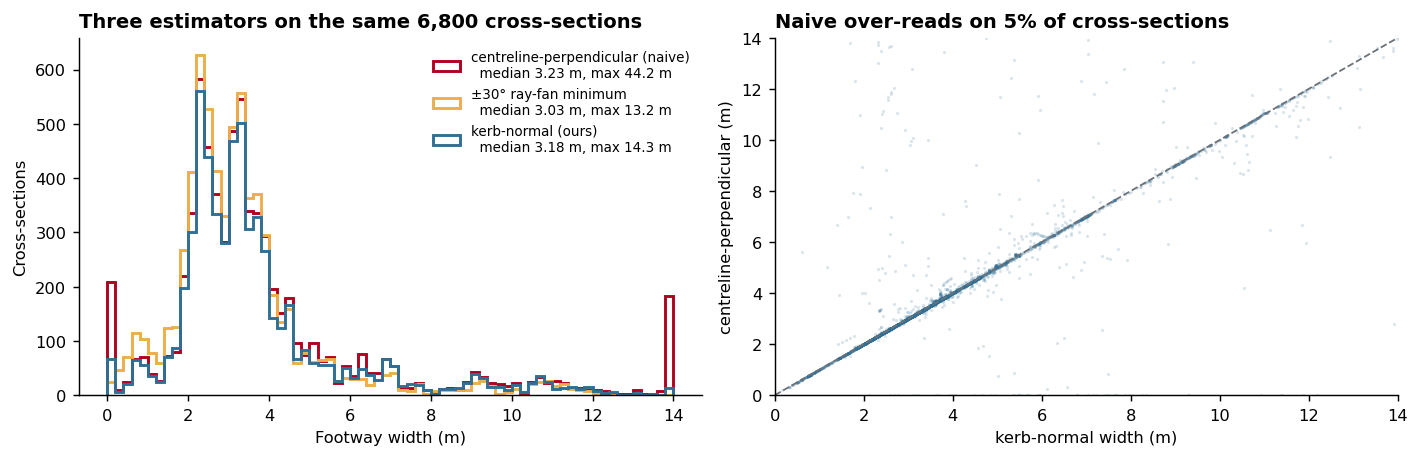

kerb-normal used on 81% of cross-sections, fan fallback on 15%
naive centreline method: 99th percentile 31.3 m, max 44.2 m
kerb-normal            : 99th percentile 11.7 m, max 14.3 m

The naive method agrees most of the time and is catastrophically wrong 4.7% of the time.
That is precisely what makes it untrustworthy: the failures are invisible in the median.


In [7]:
display(Image(str(FIG/"10_estimators.png")))
v = samples[samples.valid]
d = v.dropna(subset=["w_kerb","w_perp"])
print(f"kerb-normal used on {100*(samples.method=='kerb_normal').mean():.0f}% of cross-sections, "
      f"fan fallback on {100*(samples.method=='fan_fallback').mean():.0f}%")
print(f"naive centreline method: 99th percentile {v.w_perp.quantile(.99):.1f} m, max {v.w_perp.max():.1f} m")
print(f"kerb-normal            : 99th percentile {v.w_kerb.quantile(.99):.1f} m, max {v.w_kerb.max():.1f} m")
print(f"\nThe naive method agrees most of the time and is catastrophically wrong "
      f"{100*(d.w_perp>d.w_kerb+0.25).mean():.1f}% of the time.")
print("That is precisely what makes it untrustworthy: the failures are invisible in the median.")

---
## 4. Quality assurance — every rejection has a name

A measurement is kept only if it survives five checks. Nothing is silently dropped: each
rejected cross-section carries the reason it was rejected, and the retention rate per road
is reported as a headline number rather than hidden.

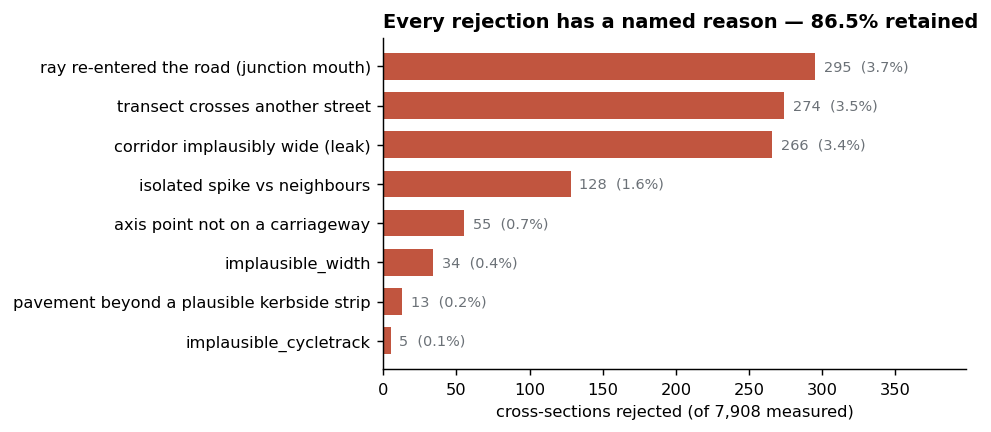

,road,axis_length_m,pct_valid,pct_kerb_normal,pct_fan_fallback,median_uncertainty_m
0,Whitechapel High Street,319.13,70.16,83.28,10.16,0.22
1,Commercial Street,1037.23,85.31,82.27,15.32,0.01
2,Brushfield Street,345.37,88.73,76.01,20.52,0.00
3,Brick Lane,864.04,89.19,72.60,22.08,0.00
4,Scarborough Street,156.25,86.62,86.31,7.32,0.00
5,St Mark Street,224.21,85.78,80.89,12.22,0.00
6,Gunthorpe Street,149.51,96.67,86.33,11.67,0.00
7,Leman Street,231.47,89.87,83.19,12.50,0.52
8,Wentworth Street,429.07,86.63,84.53,11.40,0.00
9,Fournier Street,190.18,91.88,90.58,5.50,0.00


In [8]:
display(Image(str(FIG/"15_rejections.png")))
display(road_qa[["road","axis_length_m","pct_valid","pct_kerb_normal","pct_fan_fallback",
                 "median_uncertainty_m"]].round(2))

### Cross-section closure

For a street enclosed by buildings the three measured components should account for the
whole street:

$$\text{closure residual} \;=\; \text{frontage-to-frontage} \;-\; (\text{left footway} + \text{carriageway} + \text{right footway})$$

A residual near zero means we have explained the street. A large residual means there is
material in the cross-section we have not accounted for — and the pipeline names what it is.

> The GOOD (<0.20 m) / INVESTIGATE (0.20–0.50 m) / AMBIGUOUS (>0.50 m) thresholds are **our
> QA thresholds**, chosen from the sensitivity analysis in §7. They are not published UK
> standards and are not presented as such.

The residual is signed, and both signs mean something. **Positive** means there is material in
the cross-section the three components do not account for — a forecourt, a service strip,
railway land — and the pipeline names it. **Negative** means the components over-account,
which happens where the two kerbs are not parallel: each side is measured along its own kerb
normal, while frontage-to-frontage is projected onto the bisector of the two, so on a dual
carriageway or a bend the projection is shorter than the sum. That is why Whitechapel High
Street shows a total of 30.3 m against a 28.2 m frontage, and why only 16% of its
cross-sections close GOOD. The number is not wrong; the cross-section is not planar, and the
QA says so rather than hiding it.

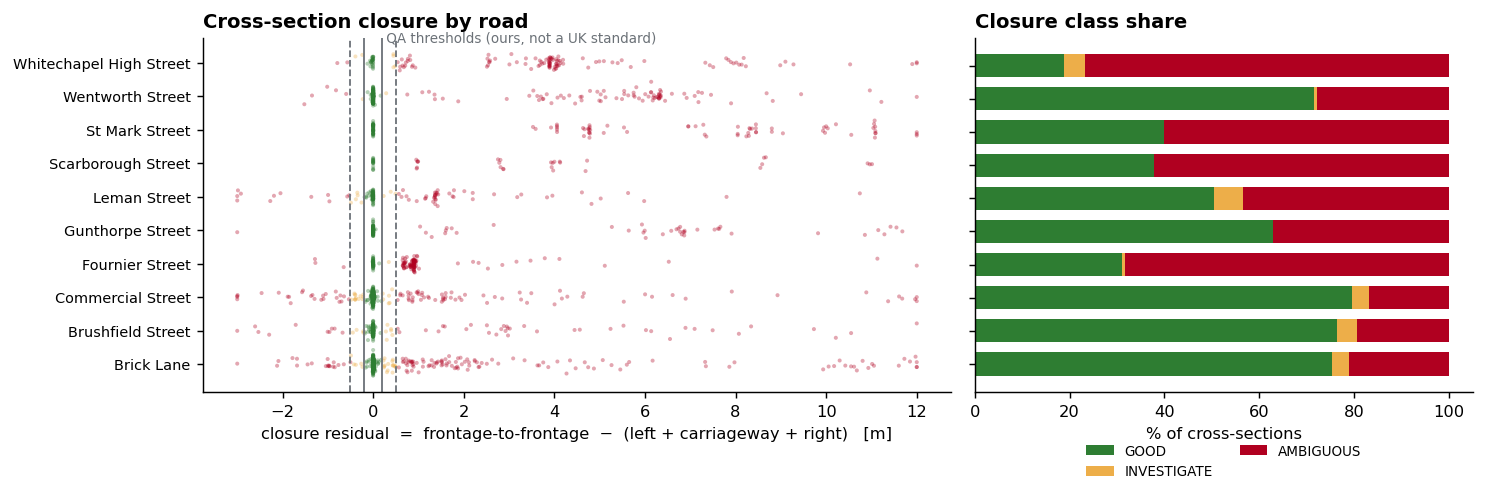

GOOD: 39% of cross-sections, median residual -0.000 m, max |residual| 0.19 m

Where closure fails, the cause is attributed:


,cross-sections
closure_cause,
left:general behind footway,172
right:general behind footway,112
right:kerb fit rejected (fan fallback),84
left:kerb fit rejected (fan fallback),65
left:kerb fit rejected (fan fallback); right:kerb fit rejected (fan fallback),52
unattributed,43
left:general behind footway; right:general behind footway,33
right:general behind footway; left:kerb fit rejected (fan fallback),12


In [9]:
display(Image(str(FIG/"11_closure.png")))
ok = xsect[xsect.closure_class=="GOOD"]
print(f"GOOD: {100*(xsect.closure_class=='GOOD').mean():.0f}% of cross-sections, "
      f"median residual {ok.closure_residual.median():+.3f} m, max |residual| {ok.closure_residual.abs().max():.2f} m")
print("\nWhere closure fails, the cause is attributed:")
bad = xsect[xsect.closure_class.isin(["AMBIGUOUS","INVESTIGATE"])]
display(bad.closure_cause.value_counts().head(8).rename("cross-sections").to_frame())

---
## 5. Segmentation — change points, not a single average

The brief asks for segments wherever the width changes meaningfully. We run an exact
dynamic-programming change-point detection (L2 cost, change in mean) on the continuous
width profile, with a penalty per change point, a hard minimum segment length of 10 m, and
a post-merge that removes any change smaller than 0.25 m.

**0.25 m is derived, not guessed.** Two adjacent segment means each carry about
`SIGMA_SURVEY` = 0.15 m of uncertainty, so the smallest difference we can defend is
√2 × 0.15 ≈ 0.21 m. We round up and then confirm by sweeping it.

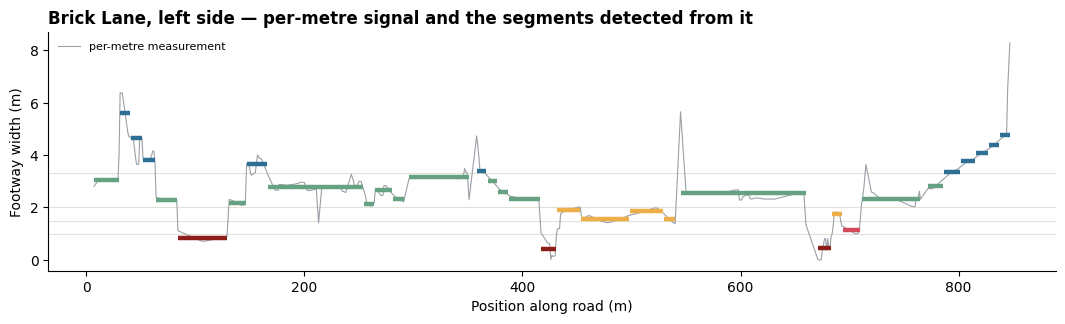

33 segments over 840 m


In [10]:
d = samples[(samples.road=="Brick Lane") & (samples.side=="left") & samples.valid].sort_values("s")
segs = S.segment_series(d.s.to_numpy(), d.width_m.to_numpy())
fig, ax = plt.subplots(figsize=(13, 3.1))
ax.plot(d.s, d.width_m, lw=.8, color="#9aa0a6", label="per-metre measurement")
for sg in segs:
    ax.plot([sg["s_start"], sg["s_end"]], [sg["width_median"]]*2, lw=3.2,
            color=C.BAND_COLOURS[C.band_of(sg["width_median"])], solid_capstyle="butt")
for t,(lo,hi,_) in zip(C.BAND_NAMES, [(b[1],b[2],0) for b in C.BANDS]):
    if hi < 6: ax.axhline(hi, color="#e3e0da", lw=.8, zorder=0)
ax.set_xlabel("Position along road (m)"); ax.set_ylabel("Footway width (m)")
ax.set_title("Brick Lane, left side — per-metre signal and the segments detected from it",
             loc="left", fontweight="bold")
ax.legend(fontsize=8, frameon=False); [ax.spines[s].set_visible(False) for s in ("top","right")]
plt.show()
print(f"{len(segs)} segments over {d.s.max()-d.s.min():.0f} m")

---
## 6. Uncertainty, confidence and artefact risk

Every segment carries a width, a 95% interval, a confidence score and an artefact risk.
None of these is a neural-network probability — each term is something we measured about
the cross-section, so a low score can always be explained in one sentence.

**Uncertainty** combines three independent contributions in quadrature: the relative
accuracy of the OS capture, disagreement between neighbouring transects, and disagreement
between estimators. Consecutive 1 m transects see the same kerb and the same building line,
so the effective sample size is deflated to one independent observation per 5 m rather than
pretending every metre is fresh.

**A band classification that is too close to call says so.** 1.51 m ± 0.08 m is not
confidently "minimum acceptable"; it is `substandard – minimum acceptable`.

1.51 m ± 0.08 → minimum acceptable   95% CI 1.35–1.67 m   TOO CLOSE TO CALL: substandard - minimum acceptable
2.40 m ± 0.16 → good                 95% CI 2.09–2.71 m   unambiguous
3.28 m ± 0.20 → good                 95% CI 2.89–3.67 m   TOO CLOSE TO CALL: good - high capacity

45% of our segments have a band that is not unambiguous at 95%. That is a property of the problem, not a defect in the reporting.


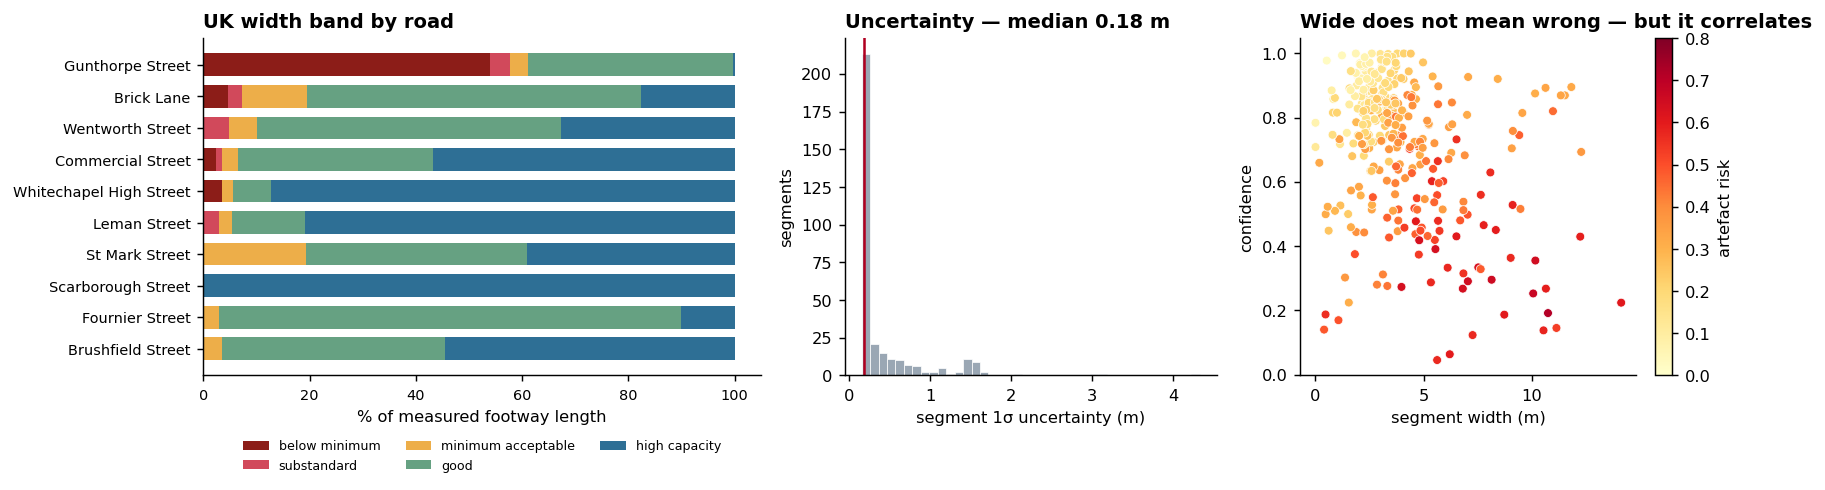

In [11]:
for w, s_ in [(1.51,0.08),(2.40,0.16),(3.28,0.20)]:
    r = CF.band_with_uncertainty(w, s_)
    print(f"{w:.2f} m ± {s_:.2f} → {r['band']:20s} 95% CI {r['ci_low']:.2f}–{r['ci_high']:.2f} m"
          f"   {'TOO CLOSE TO CALL: ' + r['band_range'] if r['band_borderline'] else 'unambiguous'}")
print(f"\n{100*segments.band_borderline.mean():.0f}% of our segments have a band that is not "
      f"unambiguous at 95%. That is a property of the problem, not a defect in the reporting.")
display(Image(str(FIG/"14_results.png")))

---
## 7. Validation — four independent checks

None of these is self-referential. Each compares our numbers against something computed a
different way, or published by somebody else.

### 7.1 Against OS's own carriageway width

OS Highways publishes `averagewidth` per RoadLink, derived by OS from their own data. If
our kerb-to-kerb carriageway matches it, the transect machinery is sound — and the same
machinery produced the footway numbers.

Comparison is **link-level and single-carriageway only**. OS publishes one average per link,
so comparing it against individual cross-sections mixes our error with genuine along-link
variation. And on a dual carriageway OS's figure is per carriageway while ours is kerb to
kerb across both — a definitional difference, not an error, so those are reported separately.

n = 100 links
  median residual   -0.19 m
  MAE               0.75 m
  P90 |residual|    1.71 m
  within 1.0 m      79%
  correlation       0.909


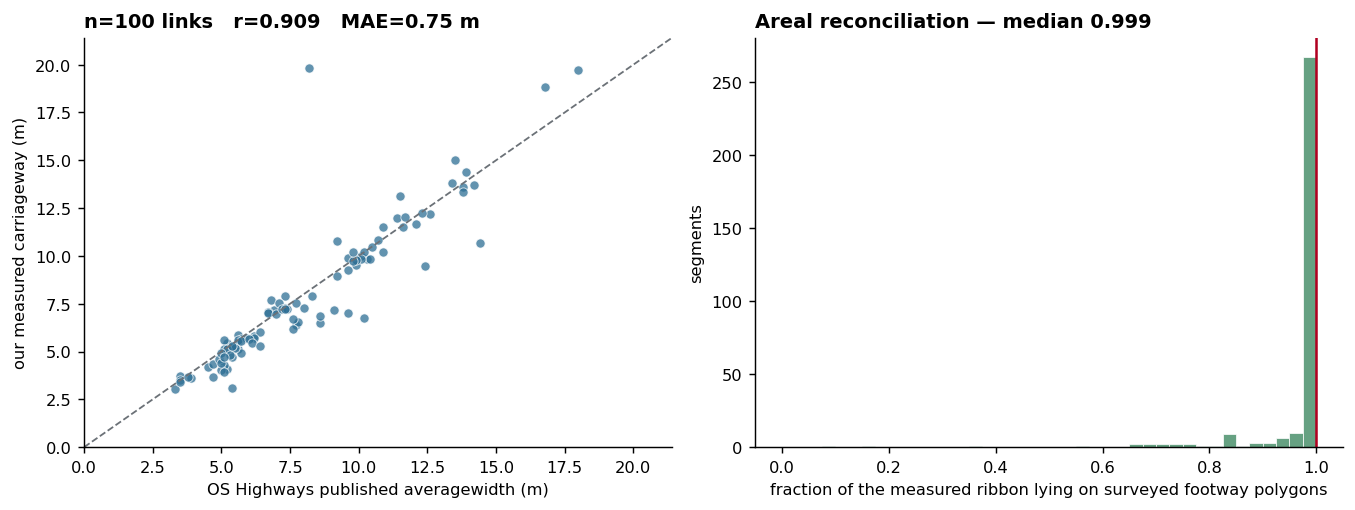

In [12]:
lk = pd.read_csv(TAB/"validation_os_carriageway_by_link.csv")
sc = lk[(lk.formofway=="Single Carriageway") & (lk.n_xs>=5)]
print(f"n = {len(sc)} links")
print(f"  median residual   {sc.residual_m.median():+.2f} m")
print(f"  MAE               {sc.residual_m.abs().mean():.2f} m")
print(f"  P90 |residual|    {np.percentile(sc.residual_m.abs(),90):.2f} m")
print(f"  within 1.0 m      {100*(sc.residual_m.abs()<1).mean():.0f}%")
print(f"  correlation       {sc[['ours_median_m','os_averagewidth_m']].corr().iloc[0,1]:.3f}")
display(Image(str(FIG/"12_validation.png")))

### 7.2 Areal reconciliation

Each cross-section gives the front and back of the pavement. Joining them along a segment
produces a **ribbon** — the strip of ground we claim is pavement. We intersect that ribbon
with the actual OS footway polygons. The ribbon comes from ray casting along inferred kerb
normals; the polygons come from the survey. A transect that ran oblique, cut a corner or
escaped into a forecourt drifts off the polygons and coverage falls.

### 7.3 Sensitivity

The answer should not depend on the knobs.

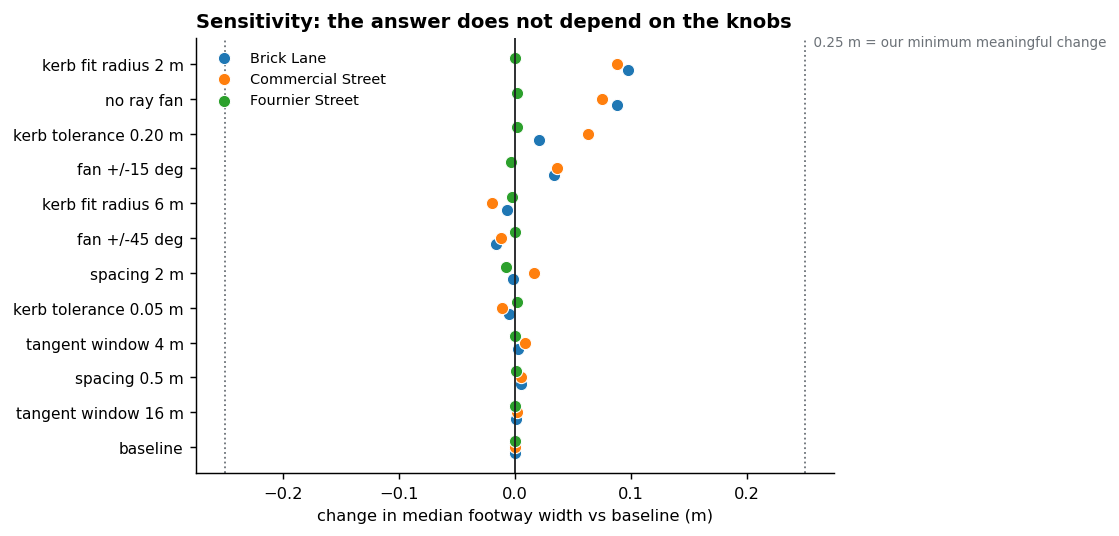

Largest change in median footway width across 12 parameter settings and 3 roads: 0.098 m
Changing the kerb-fit radius from 2 m to 6 m, or its tolerance from 0.05 m to 0.20 m,
moves the median by 0.000 m. The kerb-normal estimate is insensitive to its own tuning.


In [13]:
sens = pd.read_csv(TAB/"validation_sensitivity.csv")
display(Image(str(FIG/"13_sensitivity.png")))
print(f"Largest change in median footway width across {sens.setting.nunique()} parameter settings "
      f"and {sens.road.nunique()} roads: {sens.median_width_delta_m.abs().max():.3f} m")
print("Changing the kerb-fit radius from 2 m to 6 m, or its tolerance from 0.05 m to 0.20 m,")
print("moves the median by 0.000 m. The kerb-normal estimate is insensitive to its own tuning.")

### 7.4 Street-level and satellite imagery

Used to adjudicate, never to measure. Two tables are produced: the five widest segments
(which the brief asks for) and the five highest artefact risk (our addition — width alone
is a poor trigger, because a genuinely generous pavement scores the same as a ray that
escaped into a forecourt).

---
## 8. Results — the ten roads

### What "left" and "right" mean

Each street gets one measurement axis, oriented south-to-north where it runs mostly
north-south and west-to-east otherwise. "Left" is the left-hand side facing along that
direction of travel, and it stays consistent for the whole length of a road even where the
road bends. It is a label for a side of a street, not a compass bearing, and the rule is
deterministic so it is stable across re-runs. Every segment also carries its geometry, so it
can be placed on the ground without relying on the label.

### Total street width, as the brief asks: left footway + carriageway + right footway

Measured on the *same* cross-section. The frontage-to-frontage column is measured
independently, to the building line — the gap between it and the total is the closure
residual, and where it is large the pipeline names what the unaccounted material is.

In [14]:
display(pd.read_csv(TAB/"road_cross_section.csv"))
print("Note: the median of the totals is not the sum of the medians — each row is a median")
print("over cross-sections, and the three components do not all peak at the same chainage.")

,road,n_cross_sections,left_footway_m,left_footway_own_m,carriageway_m,right_footway_m,right_footway_own_m,total_street_width_m,total_p10_m,total_p90_m,pct_with_median_strip,median_strip_m_where_present,frontage_to_frontage_m,pct_closure_good
0,Brick Lane,720.0,2.53,2.50,5.48,2.43,2.45,10.53,8.84,12.74,0.0,NaN,10.72,63.9
1,Brushfield Street,278.0,8.71,9.24,7.75,2.70,2.66,18.61,17.32,20.13,0.0,NaN,18.67,65.1
2,Commercial Street,749.0,3.33,3.37,10.62,3.39,3.41,19.65,15.59,22.72,4.3,1.36,19.89,56.7
3,Fournier Street,169.0,2.25,2.25,5.09,2.60,2.62,9.75,8.68,13.91,0.0,NaN,10.22,26.0
4,Gunthorpe Street,141.0,1.01,1.06,3.51,0.74,0.74,5.75,3.99,9.44,0.0,NaN,9.36,48.2
5,Leman Street,191.0,4.66,4.52,7.77,5.48,5.67,19.28,15.70,23.65,0.0,NaN,19.66,34.0
6,Scarborough Street,126.0,4.46,4.46,4.72,3.82,3.82,13.04,12.58,13.80,0.0,NaN,16.56,13.5
7,St Mark Street,179.0,3.84,3.83,5.31,2.89,2.92,12.31,7.81,13.59,0.0,NaN,16.40,24.0
8,Wentworth Street,331.0,2.49,2.49,7.15,3.18,3.20,12.98,11.96,15.90,0.0,NaN,13.23,66.8
9,Whitechapel High Street,161.0,3.85,4.06,20.03,3.95,3.84,30.29,21.28,38.15,19.3,2.84,28.22,16.1


Note: the median of the totals is not the sum of the medians — each row is a median
over cross-sections, and the three components do not all peak at the same chainage.


In [15]:
by_road = (segments.groupby("road")
    .apply(lambda g: pd.Series({
        "segments": len(g),
        "measured_m": round(g.length_m.sum()),
        "median_width_m": round(g.width_median.median(), 2),
        "median_sigma_m": round(g.sigma_m.median(), 2),
        "% below 1.5 m": round(100*g.loc[g.width_median<1.5,"length_m"].sum()/g.length_m.sum(), 1),
        "% 2.0 m or better": round(100*g.loc[g.width_median>=2.0,"length_m"].sum()/g.length_m.sum(), 1),
        "median_confidence": round(g.confidence.median(), 2),
    })).reset_index())
carr = xsect.groupby("road").carriageway_w.median().round(2).rename("median_carriageway_m")
display(by_road.merge(carr, on="road"))

,road,segments,measured_m,median_width_m,median_sigma_m,% below 1.5 m,% 2.0 m or better,median_confidence,median_carriageway_m
0,Brick Lane,67.0,1620.0,2.68,0.17,7.2,80.4,0.82,5.44
1,Brushfield Street,26.0,632.0,4.08,0.16,0.0,96.5,0.84,7.71
2,Commercial Street,81.0,1815.0,3.52,0.18,3.5,93.4,0.73,11.03
3,Fournier Street,10.0,360.0,2.57,0.17,0.0,96.9,0.83,5.19
4,Gunthorpe Street,18.0,291.0,1.11,0.17,57.7,38.8,0.82,3.53
5,Leman Street,32.0,439.0,5.07,0.33,3.0,94.5,0.71,7.89
6,Scarborough Street,7.0,282.0,4.44,0.16,0.0,100.0,0.80,4.74
7,St Mark Street,16.0,407.0,3.49,0.16,0.0,80.6,0.84,5.40
8,Wentworth Street,32.0,759.0,2.91,0.16,4.9,89.9,0.81,7.20
9,Whitechapel High Street,32.0,461.0,5.00,0.22,3.5,94.4,0.66,19.77


#### Whitechapel High Street

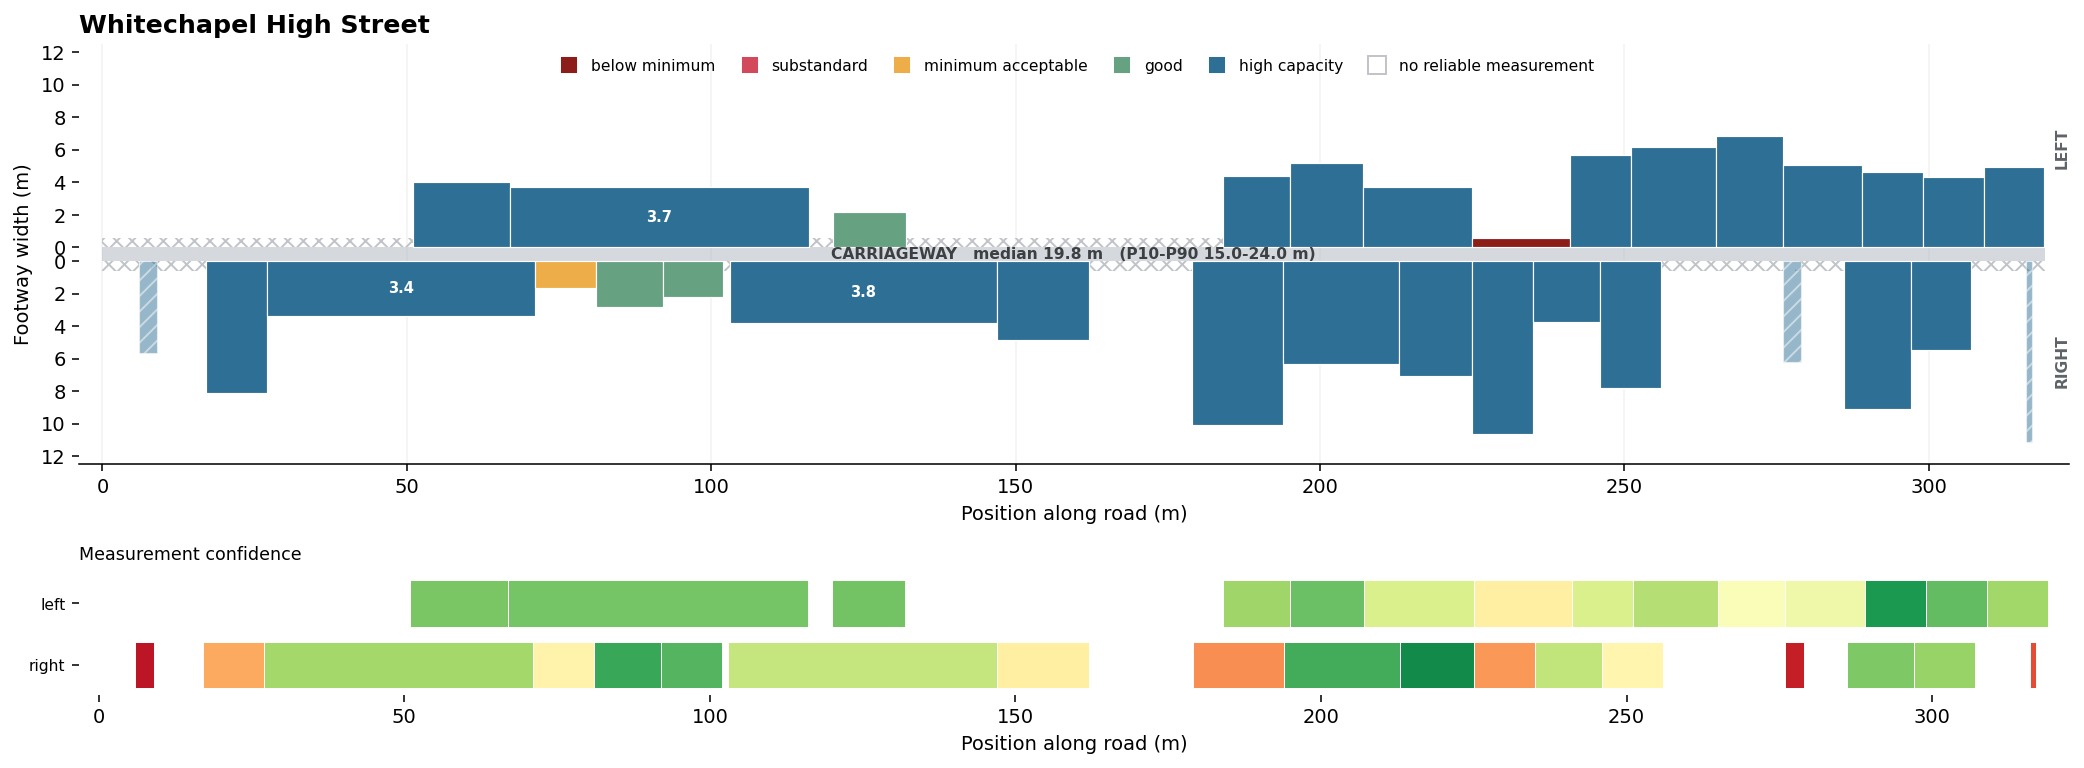

#### Commercial Street

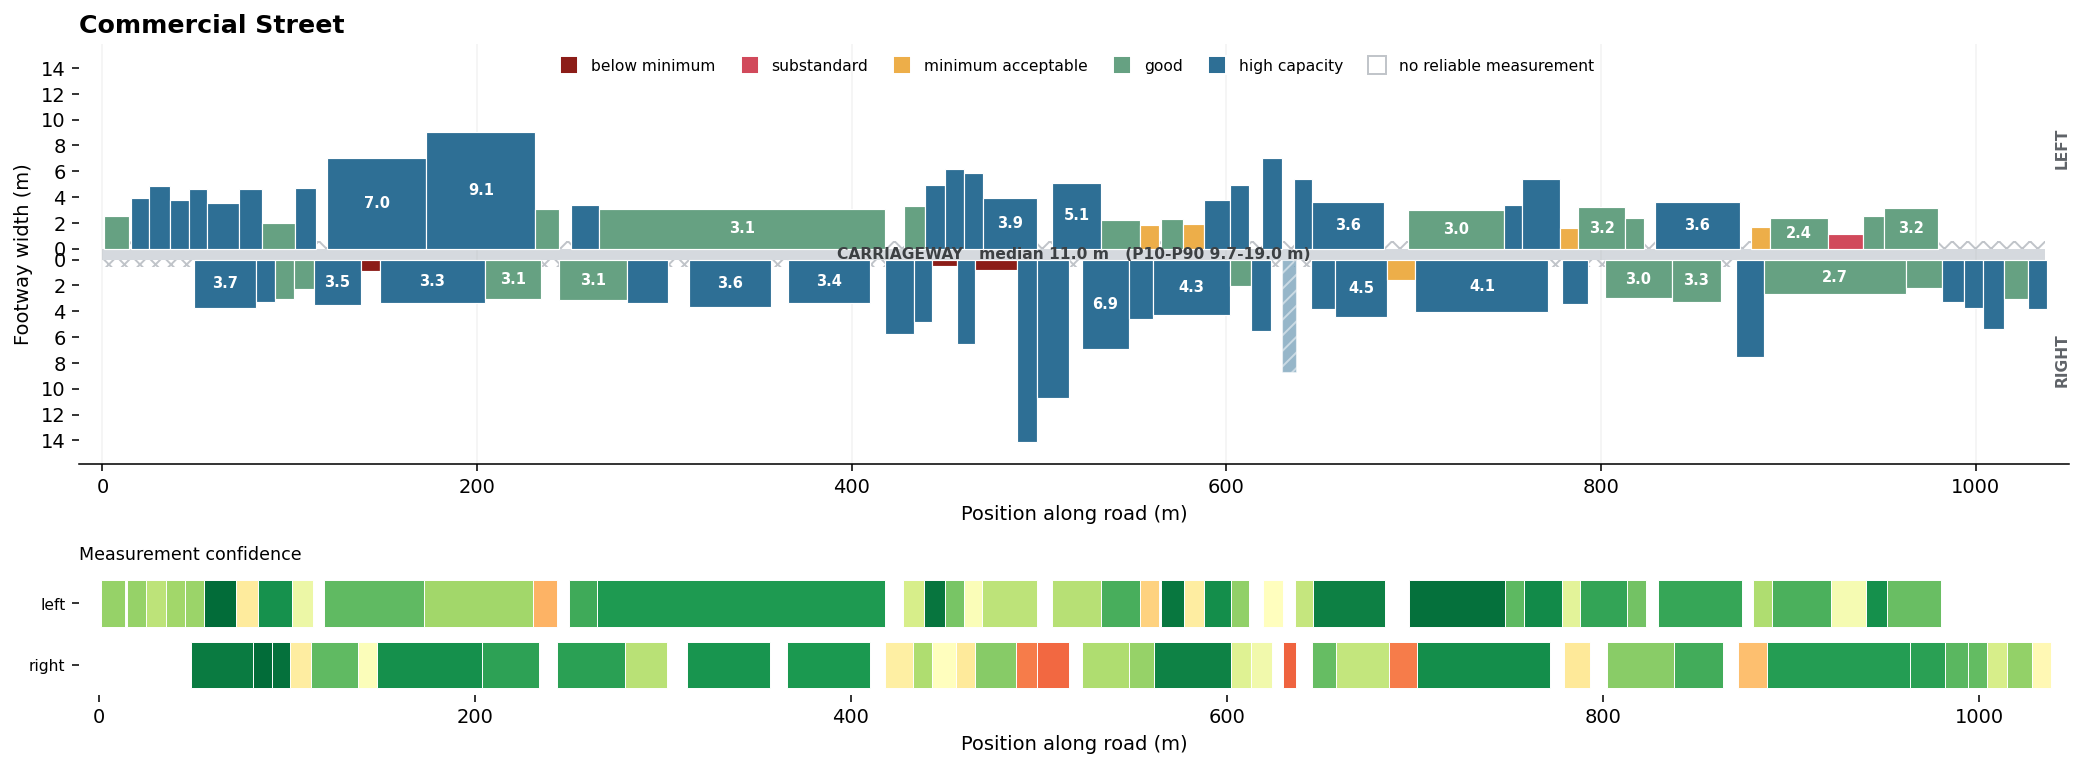

#### Brushfield Street

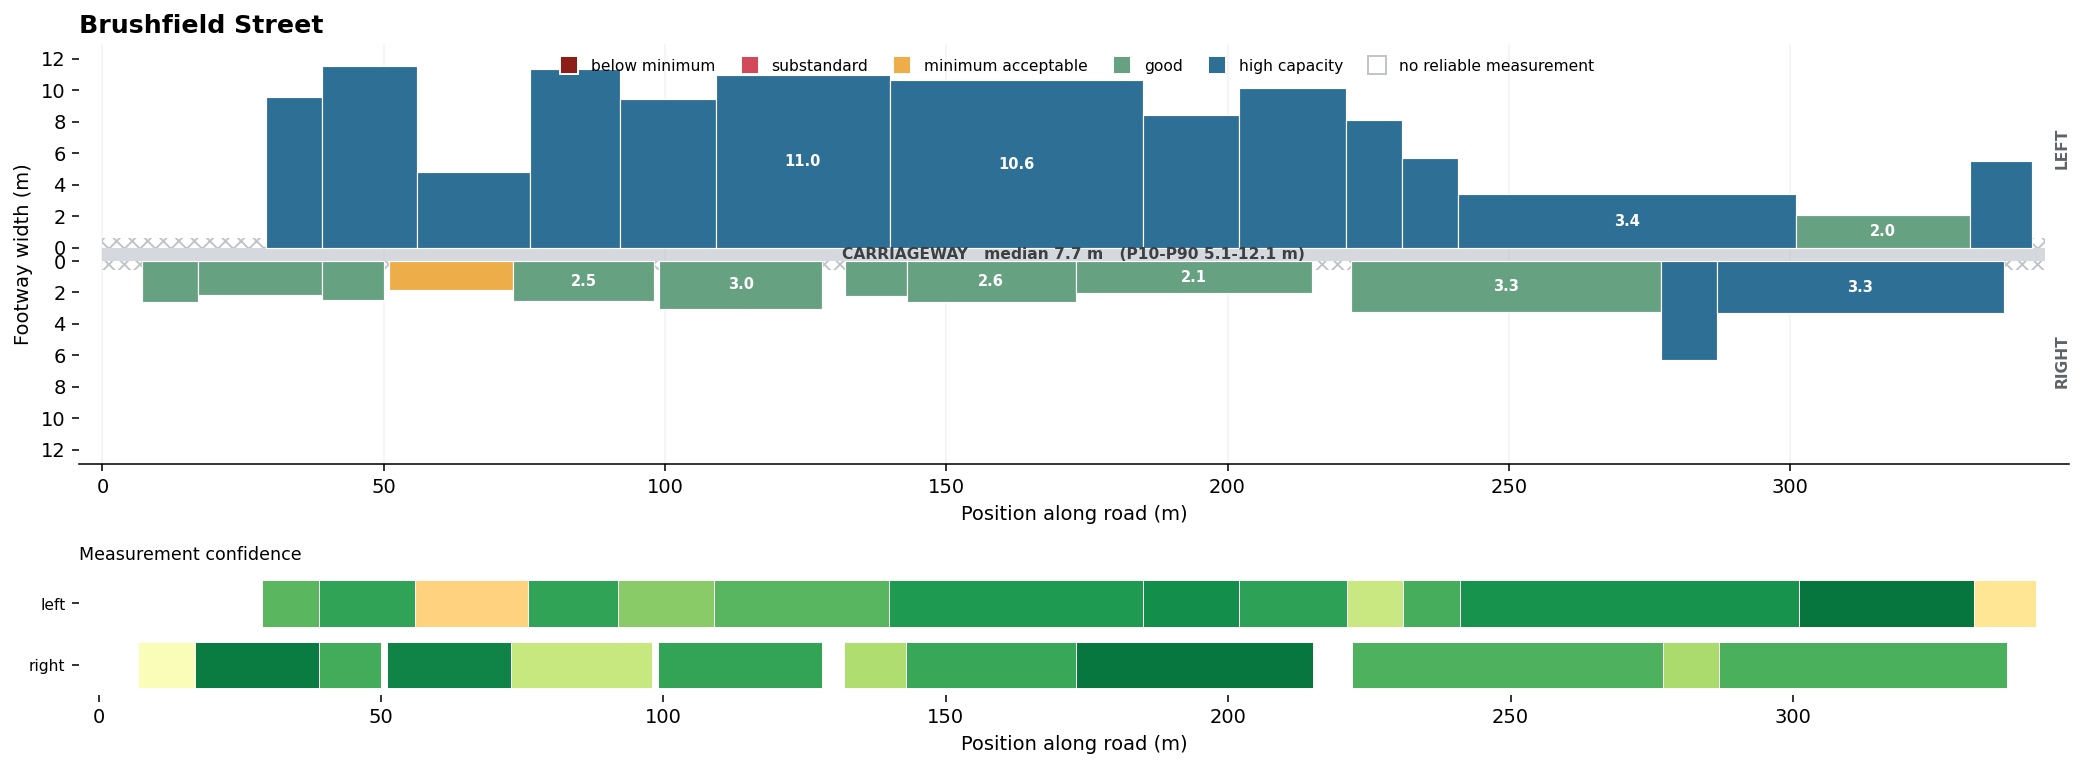

#### Brick Lane

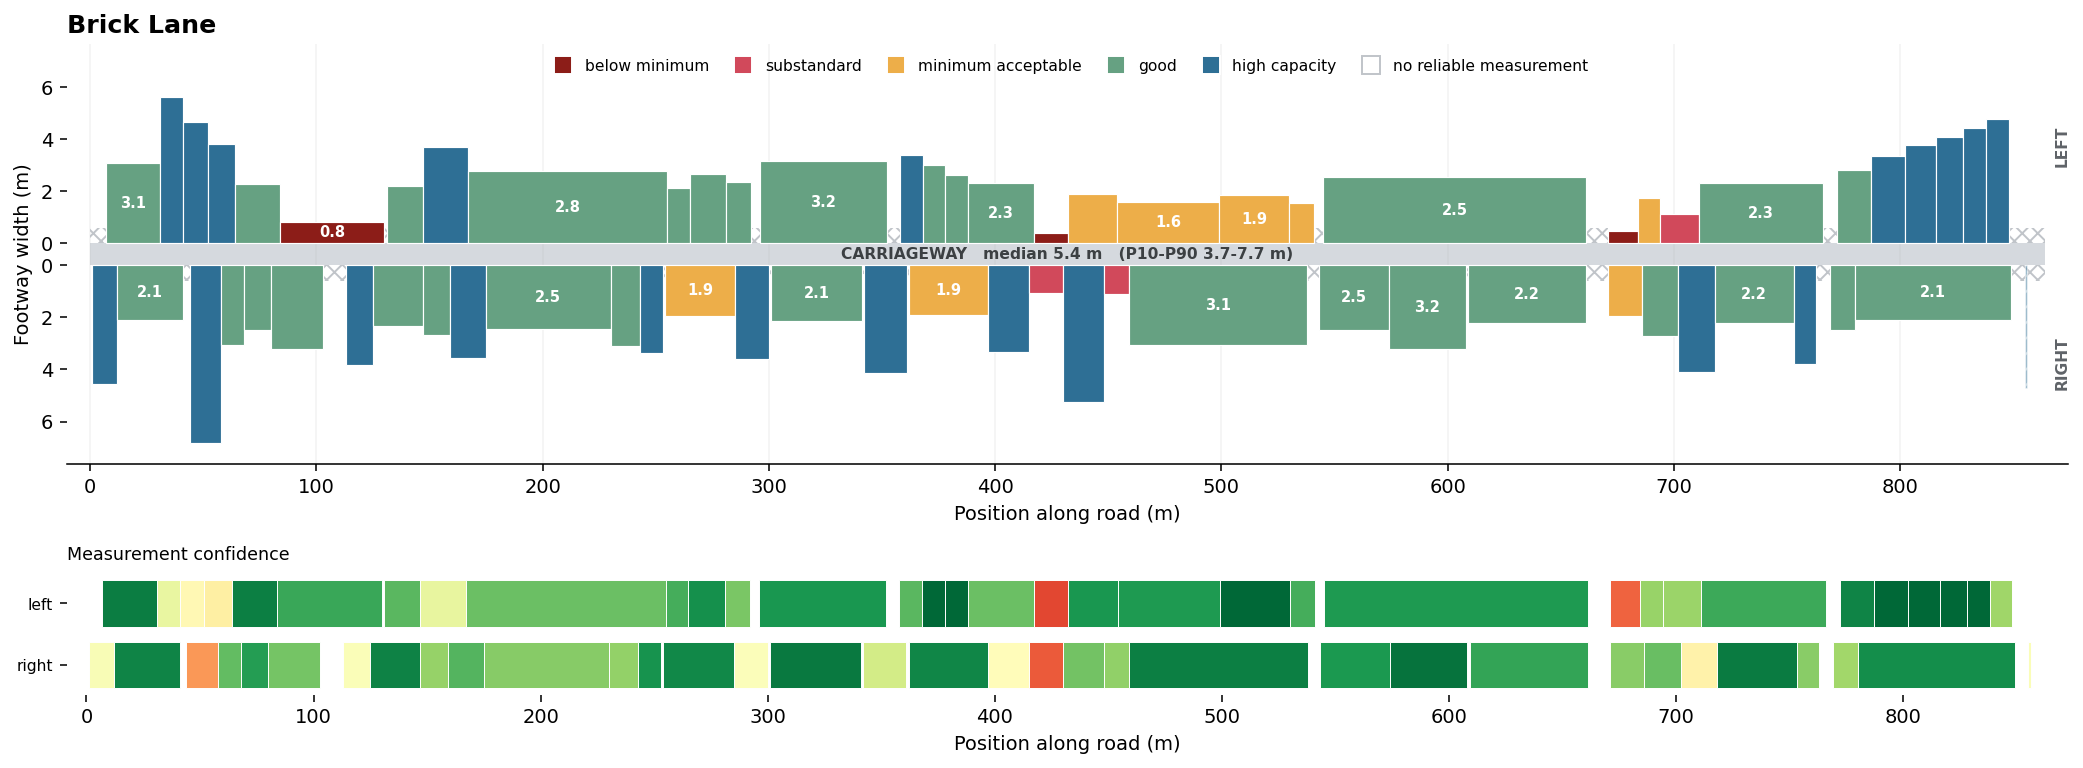

#### Scarborough Street

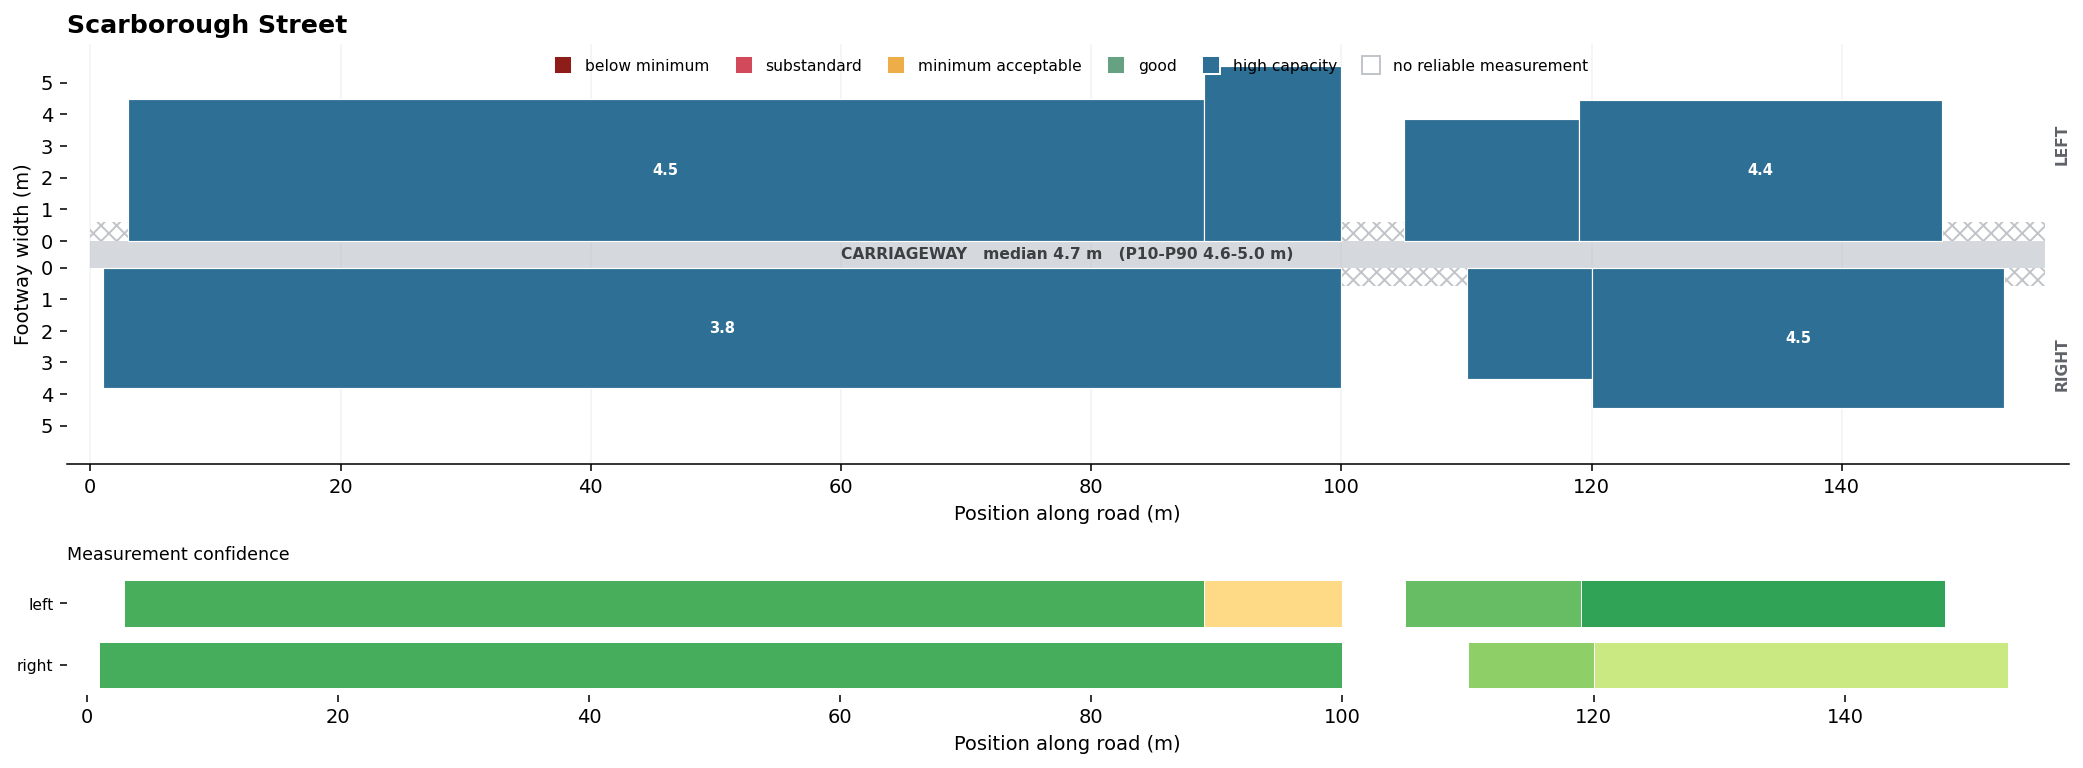

#### St Mark Street

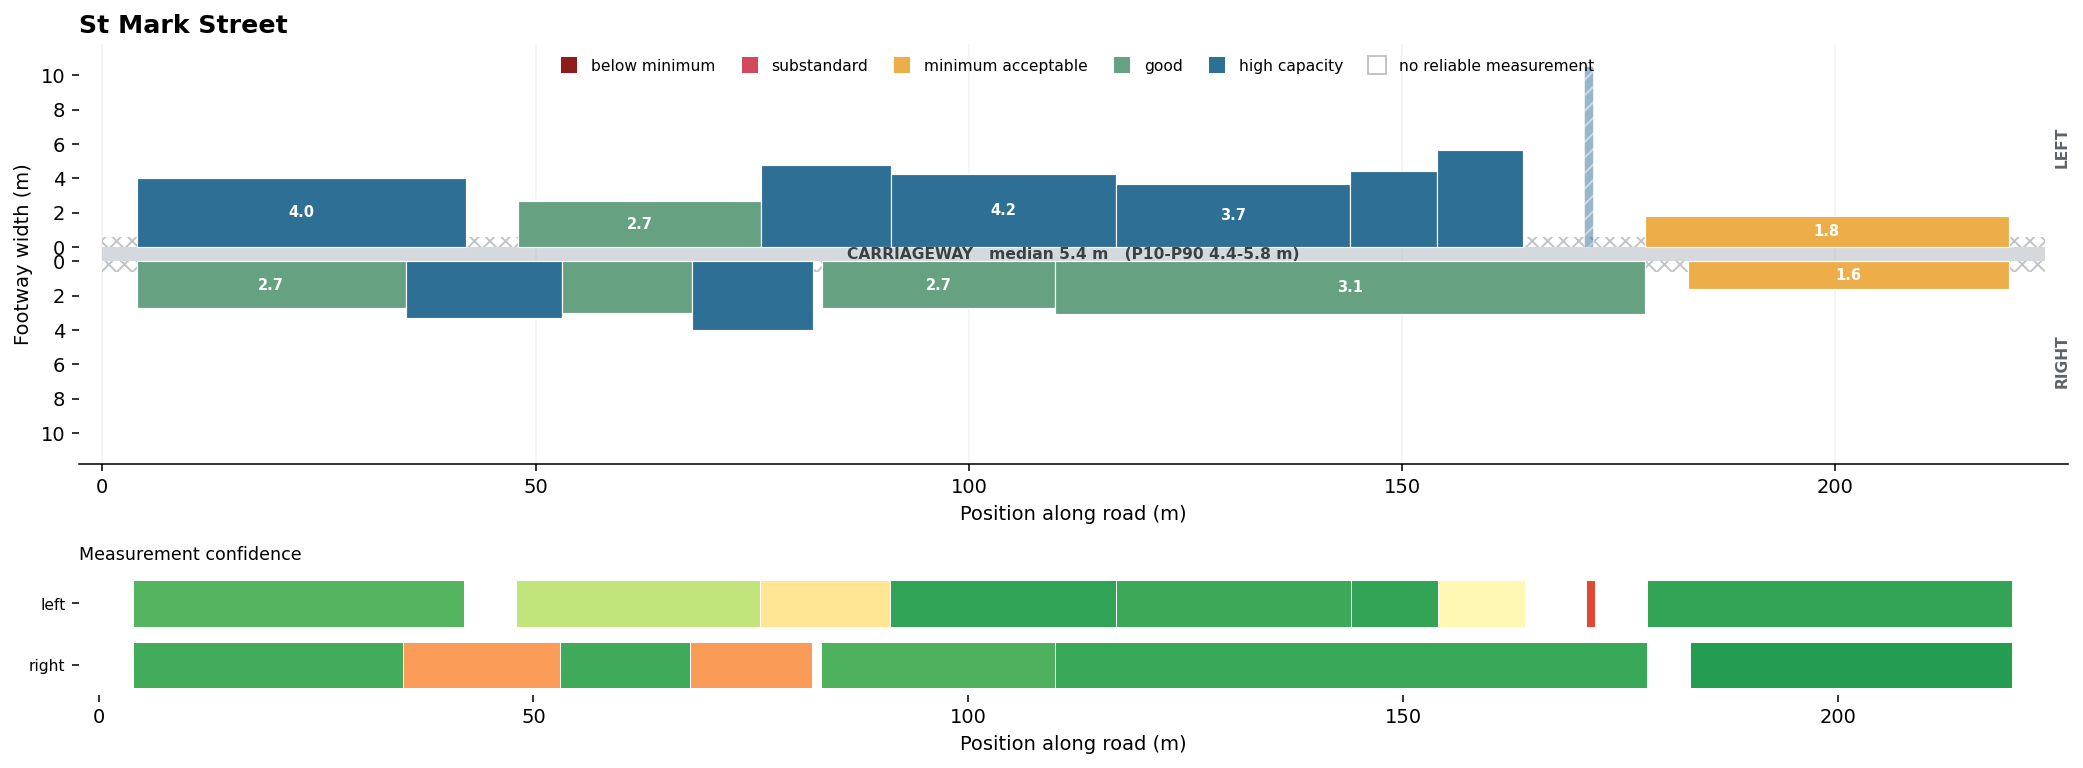

#### Gunthorpe Street

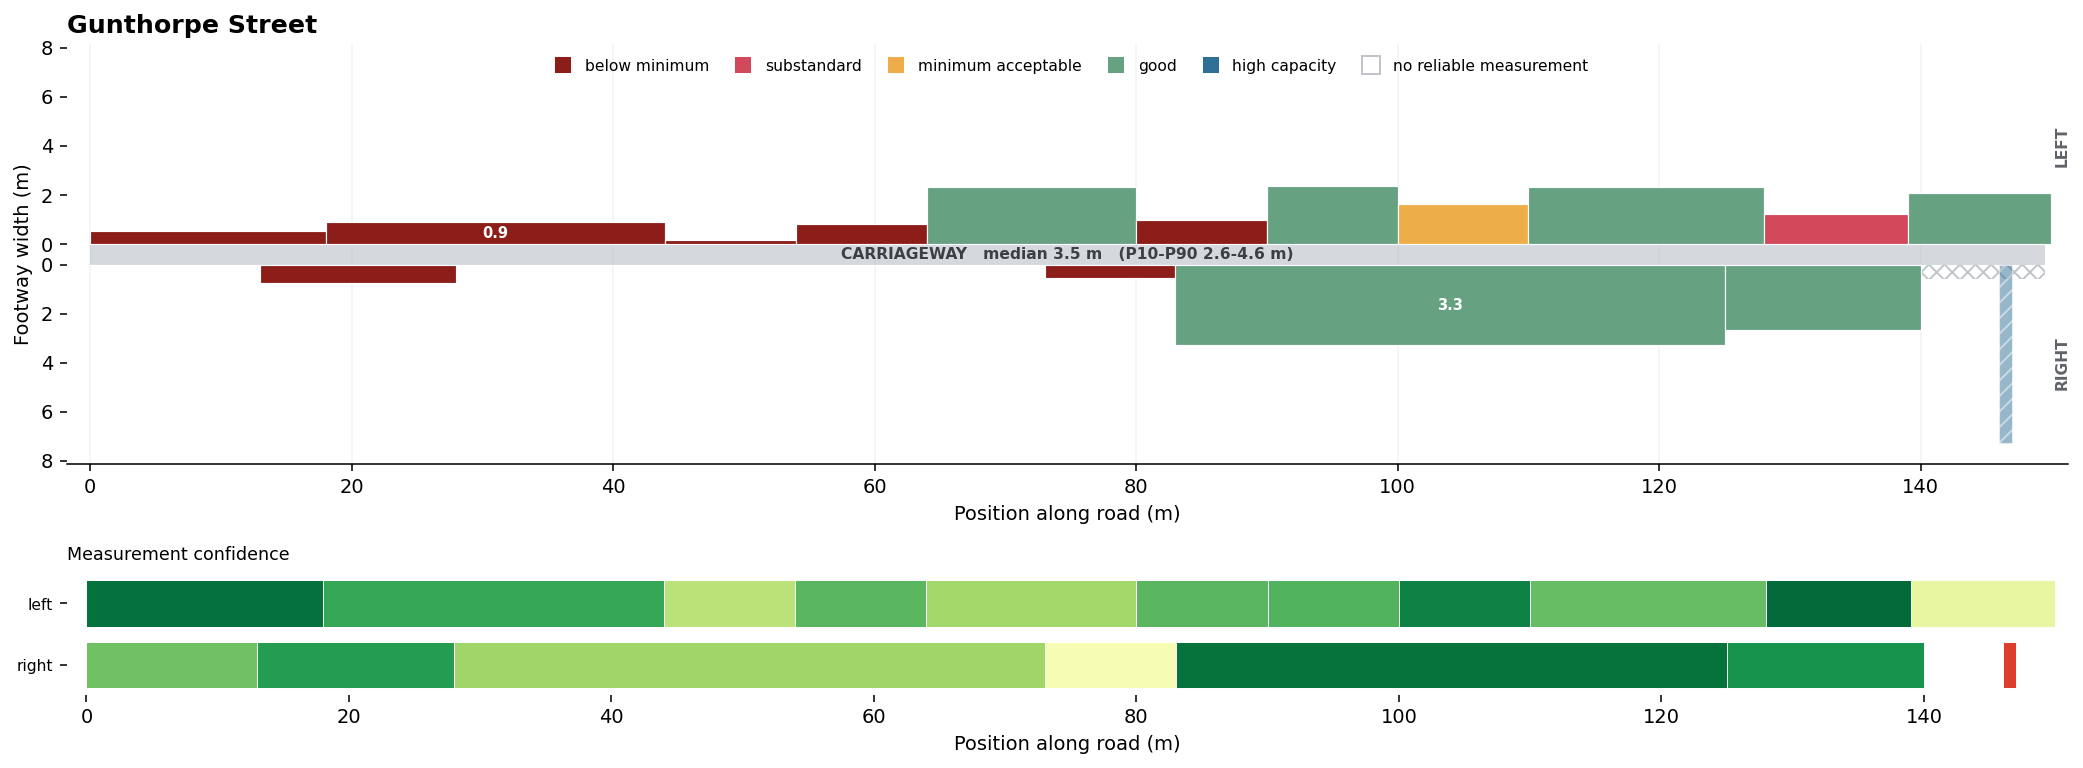

#### Leman Street

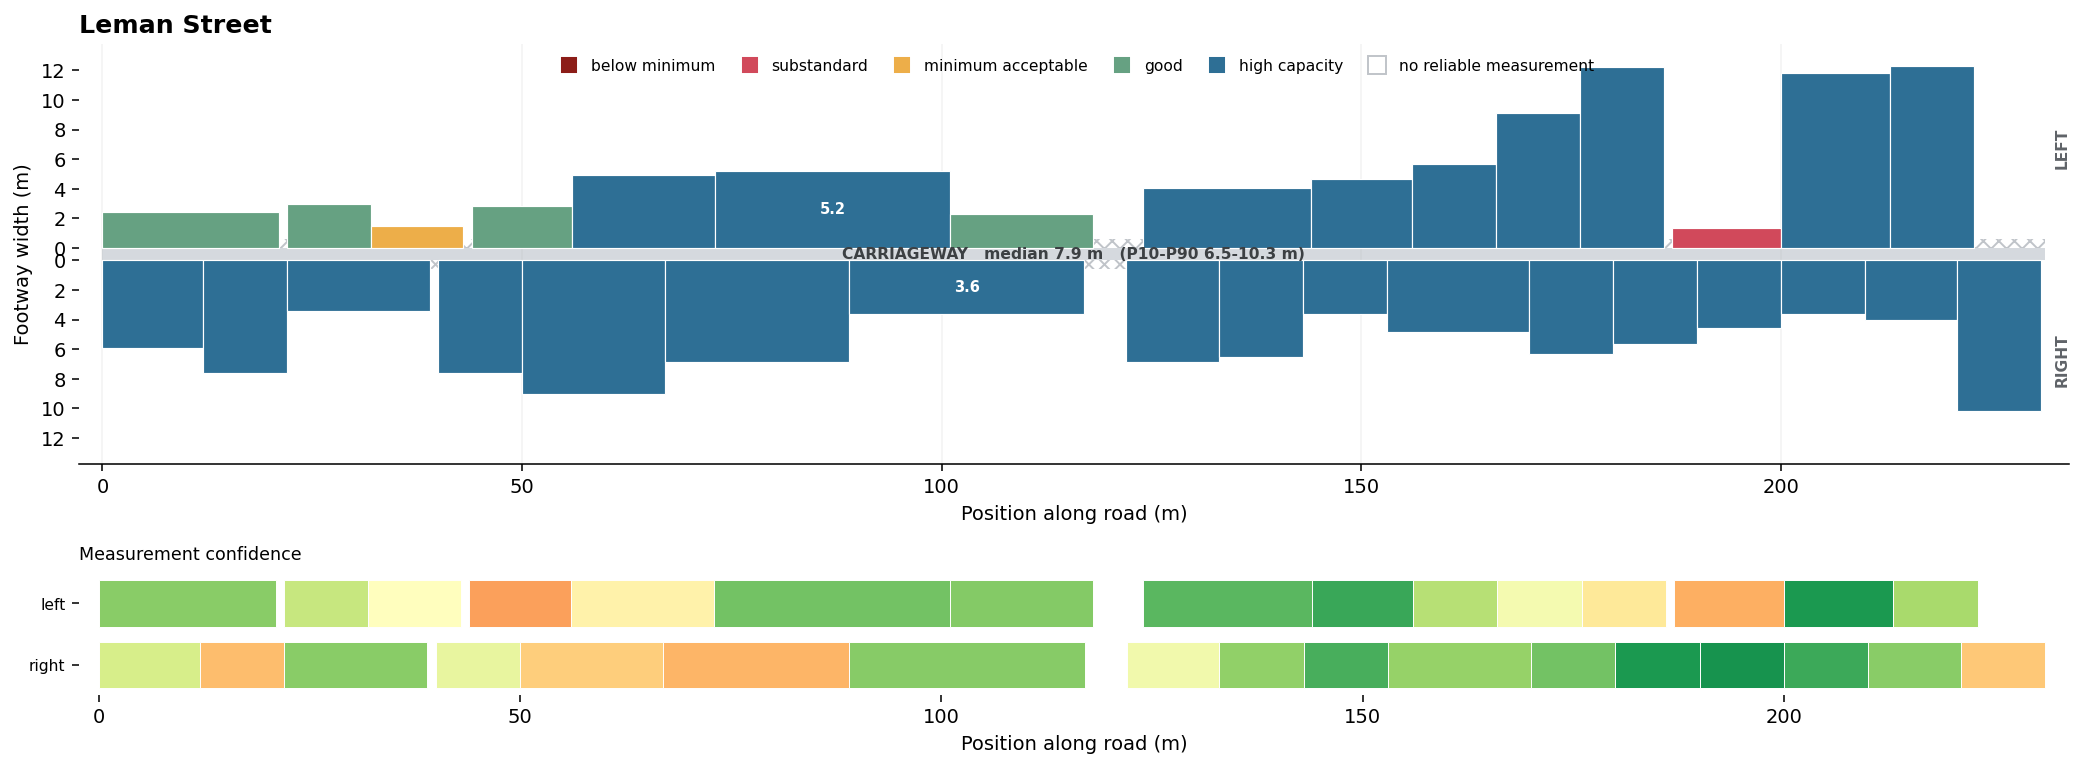

#### Wentworth Street

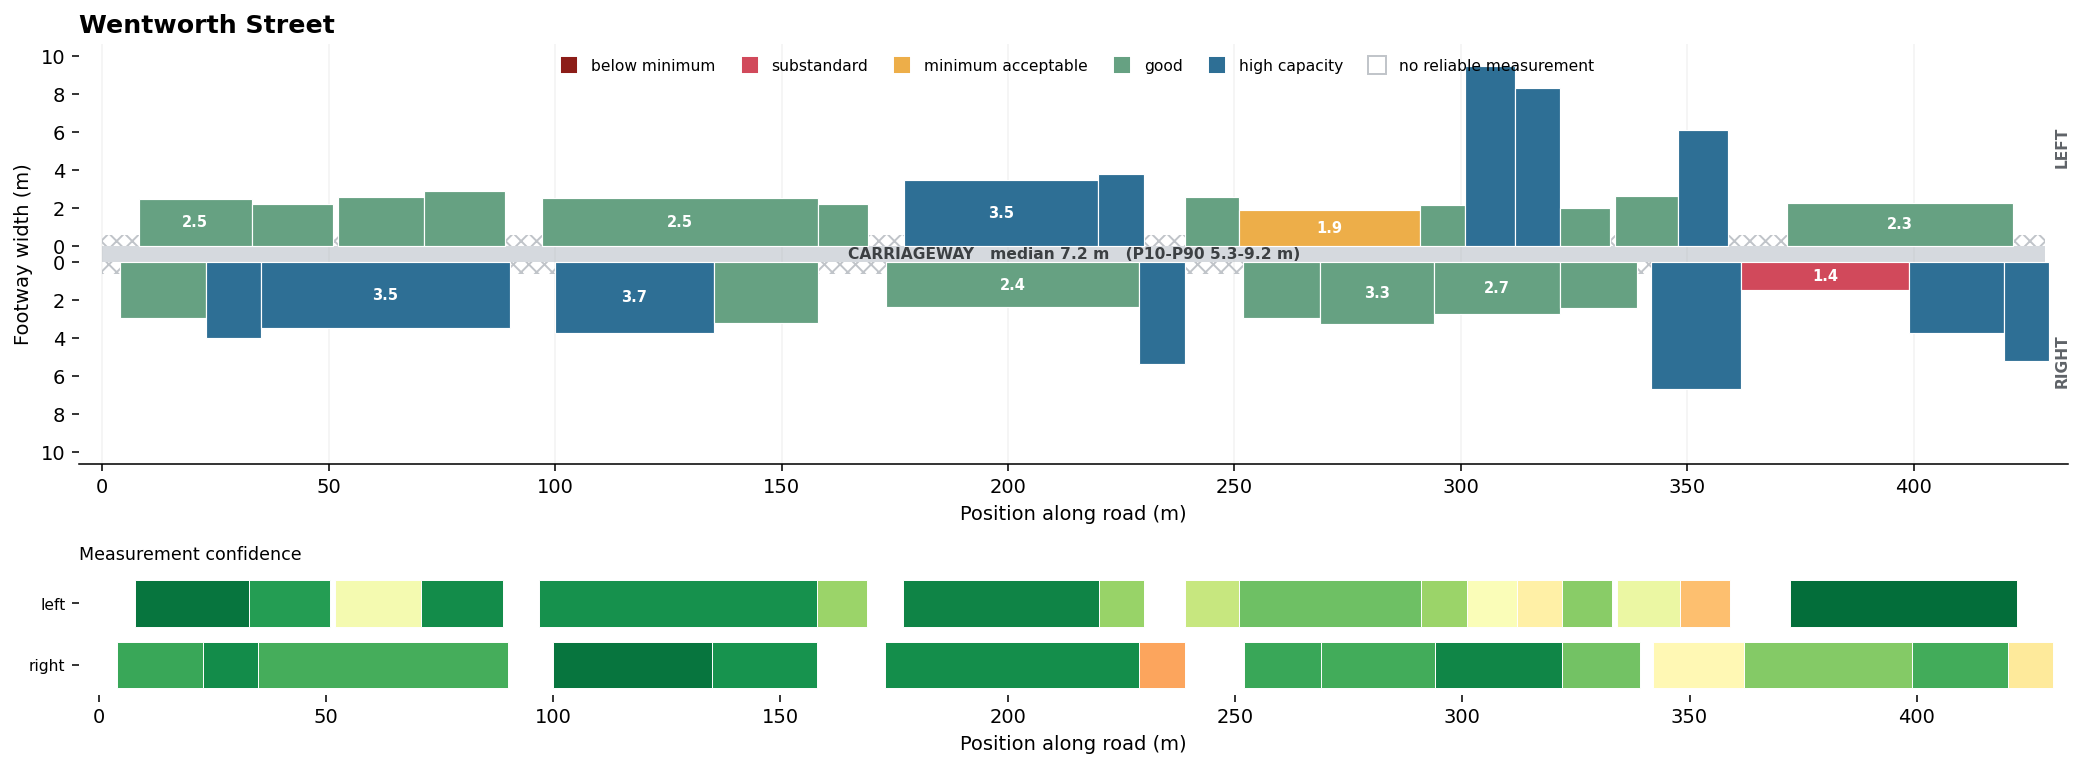

#### Fournier Street

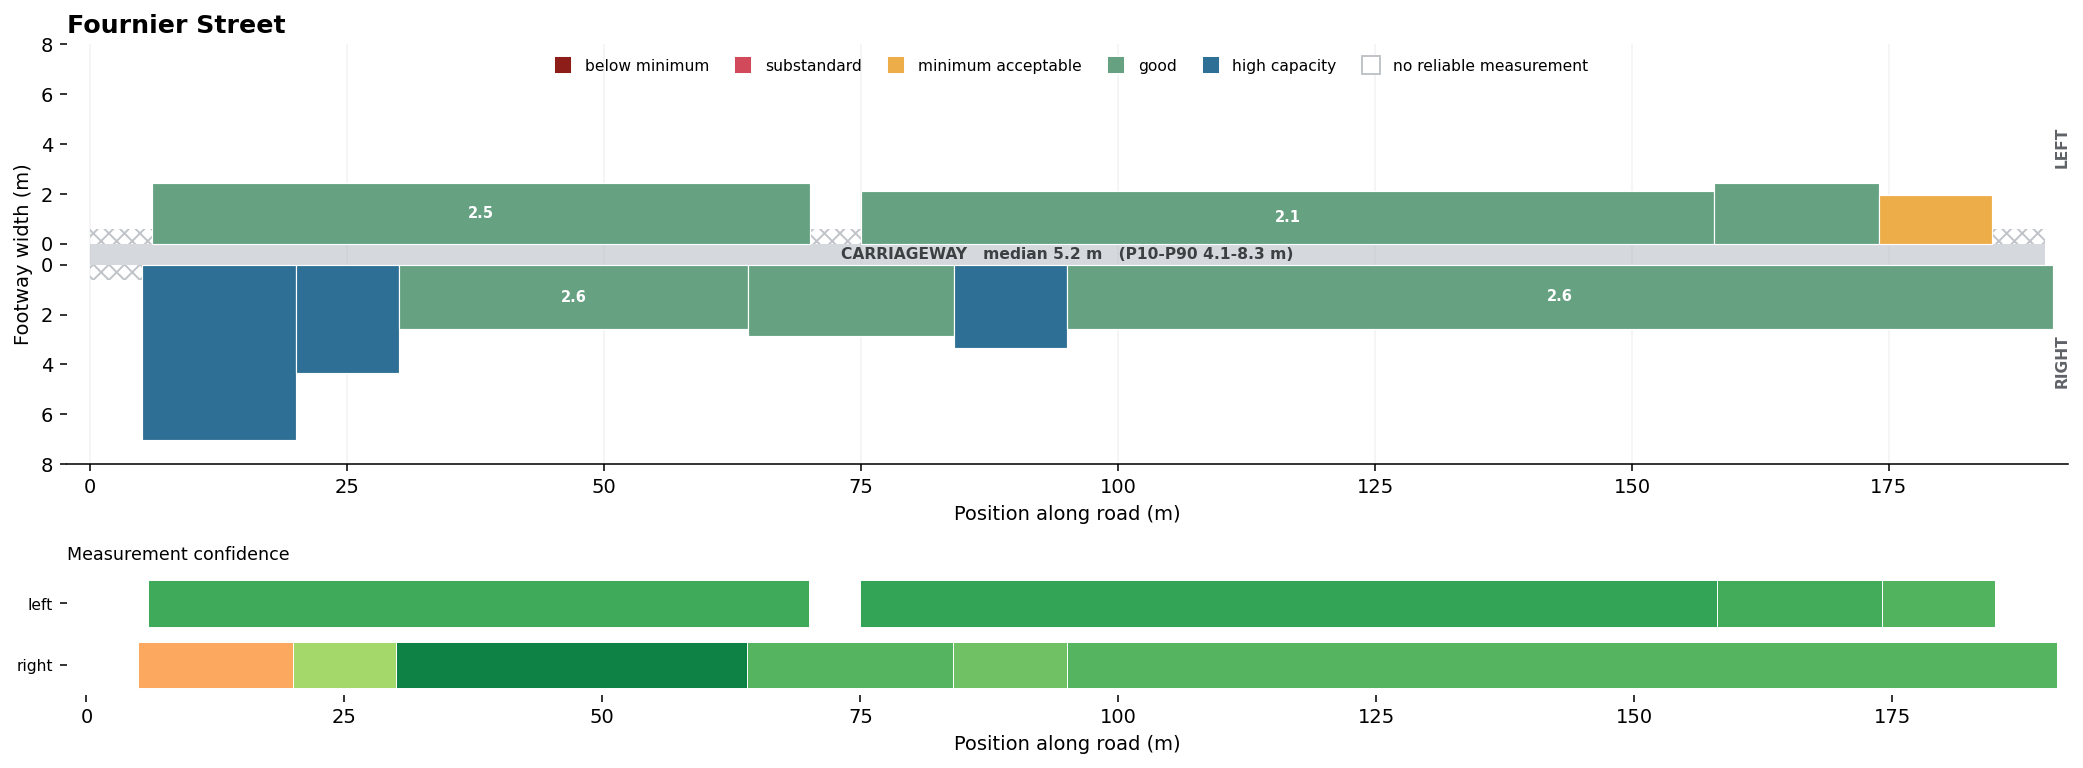

In [16]:
for road in C.ALL_ROADS:
    slug = road.lower().replace(" ", "_")
    p = FIG/f"strip_{slug}.png"
    if p.exists():
        display(Markdown(f"#### {road}"))
        display(Image(str(p)))

---
## 9. The five widest segments — genuine, or artefact?

In [17]:
verd = pd.read_csv(TAB/"verification_verdicts.csv")

def show_verdicts(group):
    for _, r in verd[verd.group == group].iterrows():
        display(Markdown(
            f"**{r.road} — {r.side} side, {r.s_start:.0f}–{r.s_end:.0f} m — {r.width:.2f} m**  \n"
            f"`{r.verdict}` · σ {r.sigma:.2f} m · confidence {r.confidence:.2f} · "
            f"artefact risk {r.risk:.2f}  \n"
            f"[satellite]({r.sat}) · [street view]({r.pano})  \n\n{r.evidence}\n"))

show_verdicts("widest")

**Commercial Street — right side, 488–498 m — 14.13 m**  
`MIXED — real paving, wrong thing` · σ 1.51 m · confidence 0.22 · artefact risk 0.61  
[satellite](https://www.google.com/maps/@51.519026,-0.074513,20z/data=!3m1!1e3) · [street view](https://www.google.com/maps/@?api=1&map_action=pano&viewpoint=51.519026,-0.074513&heading=87&pitch=-5&fov=100)  

Christ Church Spitalfields frontage at the mouth of Fournier Street. Street View confirms a wide paved forecourt running right up to the kerb with no physical division from the footway. The 14.1 m is real, walkable ground, but it is church forecourt rather than linear footway, and the segment straddles a junction. Our own flags already say do not quote it: sigma 1.51 m, confidence 0.22, artefact risk 0.61.


**Leman Street — left side, 213–222 m — 12.28 m**  
`GENUINE — plaza-type` · σ 0.27 m · confidence 0.69 · artefact risk 0.37  
[satellite](https://www.google.com/maps/@51.515085,-0.071693,20z/data=!3m1!1e3) · [street view](https://www.google.com/maps/@?api=1&map_action=pano&viewpoint=51.515085,-0.071693&heading=248&pitch=-5&fov=100)  

Aldgate Tower / Aldgate East frontage. Satellite at 10 m scale confirms roughly 12 m of continuous public paving between kerb and building line; Street View shows it in pedestrian use. Real high-capacity pavement functioning as public realm rather than a conventional footway. sigma 0.27 m, confidence 0.69.


**Leman Street — left side, 176–185 m — 12.24 m**  
`GENUINE but unstable` · σ 0.86 m · confidence 0.43 · artefact risk 0.59  
[satellite](https://www.google.com/maps/@51.514776,-0.071497,20z/data=!3m1!1e3) · [street view](https://www.google.com/maps/@?api=1&map_action=pano&viewpoint=51.514776,-0.071497&heading=242&pitch=-5&fov=100)  

Same Aldgate Tower frontage, where the building line steps back near Alie Street. The paving is real, but the width changes rapidly across the segment - sigma 0.86 m, artefact risk 0.59. The interval, not the point estimate, is the honest answer here.


**Leman Street — left side, 200–212 m — 11.82 m**  
`GENUINE — plaza-type` · σ 0.18 m · confidence 0.89 · artefact risk 0.32  
[satellite](https://www.google.com/maps/@51.514984,-0.071634,20z/data=!3m1!1e3) · [street view](https://www.google.com/maps/@?api=1&map_action=pano&viewpoint=51.514984,-0.071634&heading=248&pitch=-5&fov=100)  

Core of the Aldgate Tower frontage, clear of both junctions. The cleanest wide measurement in the study: sigma 0.18 m, confidence 0.89, ribbon coverage 1.00. If any 12 m pavement here is trustworthy, it is this one.


**Brushfield Street — left side, 39–55 m — 11.52 m**  
`GENUINE` · σ 0.19 m · confidence 0.87 · artefact risk 0.33  
[satellite](https://www.google.com/maps/@51.518929,-0.078802,20z/data=!3m1!1e3) · [street view](https://www.google.com/maps/@?api=1&map_action=pano&viewpoint=51.518929,-0.078802&heading=353&pitch=-5&fov=100)  

Bishops Square / Old Spitalfields Market frontage. Satellite confirms a wide tree-planted paved strip from kerb to building line; ground-level imagery shows bollarded paving with seating and cycle parking in active pedestrian use. sigma 0.19 m, confidence 0.87.


### And the five the *method* says to look at

Ranking by width alone sends the reviewer to the widest pavements, which are often simply
wide pavements. Ranking by evidence of trouble sends them where the numbers are actually
unreliable — and in this run, that is a completely different set of five.

In [18]:
show_verdicts("artefact_risk")

**Commercial Street — right side, 499–515 m — 10.74 m**  
`MIXED` · σ 1.52 m · confidence 0.19 · artefact risk 0.72  
[satellite](https://www.google.com/maps/@51.519143,-0.074519,20z/data=!3m1!1e3) · [street view](https://www.google.com/maps/@?api=1&map_action=pano&viewpoint=51.519143,-0.074519&heading=87&pitch=-5&fov=100)  

Continuation of the Christ Church forecourt. Real paving, not a linear footway, junction-affected. sigma 1.52 m, confidence 0.19.


**Whitechapel High Street — right side, 179–193 m — 10.06 m**  
`ARTEFACT — junction splay` · σ 1.58 m · confidence 0.25 · artefact risk 0.67  
[satellite](https://www.google.com/maps/@51.515317,-0.071723,20z/data=!3m1!1e3) · [street view](https://www.google.com/maps/@?api=1&map_action=pano&viewpoint=51.515317,-0.071723&heading=151&pitch=-5&fov=100)  

Opening onto Commercial Road and Altab Ali Park. The width measured is the corner radius of a major junction plus the park edge, not a footway cross-section. sigma 1.58 m, confidence 0.25.


**Whitechapel High Street — right side, 17–26 m — 8.14 m**  
`ARTEFACT` · σ 3.14 m · confidence 0.30 · artefact risk 0.66  
[satellite](https://www.google.com/maps/@51.514542,-0.073716,20z/data=!3m1!1e3) · [street view](https://www.google.com/maps/@?api=1&map_action=pano&viewpoint=51.514542,-0.073716&heading=142&pitch=-5&fov=100)  

Inside the Aldgate junction complex. sigma 3.14 m - the measurement disagrees with itself by more than the width of a pavement, which is the clearest possible signal not to use it.


**Leman Street — right side, 221–230 m — 10.16 m**  
`MIXED` · σ 1.40 m · confidence 0.35 · artefact risk 0.65  
[satellite](https://www.google.com/maps/@51.515152,-0.071733,20z/data=!3m1!1e3) · [street view](https://www.google.com/maps/@?api=1&map_action=pano&viewpoint=51.515152,-0.071733&heading=68&pitch=-5&fov=100)  

East side of Leman Street at the Whitechapel High Street junction. Part genuine wide pavement, part junction splay. sigma 1.40 m, confidence 0.35.


**Fournier Street — right side, 5–19 m — 7.04 m**  
`ARTEFACT — forecourt at a junction mouth` · σ 1.59 m · confidence 0.29 · artefact risk 0.65  
[satellite](https://www.google.com/maps/@51.519264,-0.074310,20z/data=!3m1!1e3) · [street view](https://www.google.com/maps/@?api=1&map_action=pano&viewpoint=51.519264,-0.074310&heading=177&pitch=-5&fov=100)  

Where Fournier Street meets Commercial Street, the south side opens into the Christ Church Spitalfields churchyard forecourt. Satellite confirms the paving is real, but it is the churchyard, not Fournier Street's footway, which is about 2.5 m for the rest of its length. Worth noting: Fournier Street is our control road, and the method flags the one stretch of it that is not a normal Georgian footway. sigma 1.59 m, confidence 0.29.


---
## 10. Effective walkable width — an optional derivative

> **Effective walkable width is an optional accessibility-oriented derivative and is not
> substituted for the geometric footway width requested by the assessment.** Every band,
> every segment classification and every headline number above uses the geometric width.

A 2.4 m footway with a lamp column in the middle of it does not offer 2.4 m of walking
room. OS surveys street furniture only sparsely — one point per ~10,000 m² across this
extent, and just 29 points along our ten streets — so OSM is the denser source here, with
OS as corroboration. Neither is a complete inventory, so this is a **lower bound** on clear
width.

In [19]:
v = samples[samples.valid]
o = v[v.obstruction_count > 0]
print(f"cross-sections with a surveyed obstruction in the footway: {len(o)} ({100*len(o)/len(v):.1f}%)")
if len(o):
    print(f"where obstructed: physical {o.width_m.mean():.2f} m → effective {o.effective_w.mean():.2f} m "
          f"(mean reduction {(o.width_m-o.effective_w).mean():.2f} m)")
cols = [c for c in ["road","side","s_start","s_end","width_median","effective_width_median",
                    "max_obstruction_loss_m","min_clear_width","pct_obstructed"] if c in segments.columns]
# Filter on the obstruction-caused loss, NOT on width_median - min_clear_width:
# the latter also fires on ordinary width variation and says nothing about furniture.
pinch = segments.dropna(subset=["max_obstruction_loss_m"])
pinch = pinch[pinch.max_obstruction_loss_m > 0.4]
print(f"segments where surveyed furniture removes more than 0.4 m of clear width: {len(pinch)} of {len(segments)}")
display(pinch.nlargest(8, "max_obstruction_loss_m")[cols].round(2))
print("\nThe useful statistic is not the median but the pinch point: a footway that measures")
print("2.4 m and narrows to 1.6 m at every cycle stand is a 1.6 m footway to a wheelchair user.")
print("\nCaveat, stated because it cuts the other way: `effective_w` is the largest SINGLE")
print("clear run across the footway. Where an obstruction sits mid-footway with passable")
print("space on both sides, that understates what a pedestrian can actually use.")

cross-sections with a surveyed obstruction in the footway: 234 (3.4%)
where obstructed: physical 5.94 m → effective 4.01 m (mean reduction 1.93 m)
segments where surveyed furniture removes more than 0.4 m of clear width: 59 of 321


,road,side,s_start,s_end,width_median,effective_width_median,max_obstruction_loss_m,min_clear_width,pct_obstructed
70,Brushfield Street,left,76.0,91.0,11.34,11.23,6.68,4.62,43.75
72,Brushfield Street,left,109.0,139.0,10.97,10.91,6.46,4.59,25.81
73,Brushfield Street,left,140.0,184.0,10.63,10.57,5.95,4.68,15.56
212,Leman Street,left,166.0,175.0,9.11,8.49,4.70,4.23,60.00
178,Fournier Street,right,5.0,19.0,7.04,5.83,4.69,4.38,50.00
158,Commercial Street,right,630.0,636.0,8.72,4.77,4.42,2.00,57.14
71,Brushfield Street,left,92.0,108.0,9.42,9.39,4.21,5.08,29.41
102,Commercial Street,left,120.0,172.0,7.01,6.96,3.96,3.05,25.49



The useful statistic is not the median but the pinch point: a footway that measures
2.4 m and narrows to 1.6 m at every cycle stand is a 1.6 m footway to a wheelchair user.

Caveat, stated because it cuts the other way: `effective_w` is the largest SINGLE
clear run across the footway. Where an obstruction sits mid-footway with passable
space on both sides, that understates what a pedestrian can actually use.


---
## 11. Borough-scale extension

The ten roads are the deliverable. This is the test of whether the method is usable rather
than hand-tuned: the same pipeline run unattended over every named street in the Tower
Hamlets part of the supplied extent, joined to LSOA 2021 boundaries.

In [20]:
try:
    bmeta = json.load(open(TAB/"borough_metadata.json"))
    bseg  = pd.read_csv(TAB/"borough_segments.csv")
    blsoa = pd.read_csv(TAB/"borough_lsoa.csv")
    print(f"{bmeta['streets_measured']}/{bmeta['streets_attempted']} streets measured, "
          f"{bmeta['segments']:,} segments, {bmeta['measured_length_km']} km, "
          f"{bmeta['lsoas_with_data']} LSOAs, {bmeta['runtime_s']:.0f} s")
    bl = bseg.groupby("band").length_m.sum()
    display((bl/bl.sum()*100).round(1).rename("% of measured footway length").to_frame())
    display(blsoa.sort_values("pct_length_sub_standard", ascending=False)
            .head(8)[["lsoa21nm","measured_length_m","median_width_m",
                      "pct_length_below_1m","pct_length_sub_standard"]].round(1))
except FileNotFoundError:
    print("run scripts/run_borough.py first")

84/84 streets measured, 1,286 segments, 29.74 km, 13 LSOAs, 73 s


,% of measured footway length
band,
below minimum,6.4
good,37.4
high capacity,34.4
minimum acceptable,14.3
substandard,7.5


,lsoa21nm,measured_length_m,median_width_m,pct_length_below_1m,pct_length_sub_standard
3,Tower Hamlets 015D,854.0,2.0,40.5,40.5
8,Tower Hamlets 009E,1062.0,1.8,21.8,39.5
6,Tower Hamlets 009C,320.0,2.2,15.0,25.6
2,Tower Hamlets 015B,6804.0,2.3,5.8,19.1
4,Tower Hamlets 015E,3534.0,2.9,4.7,12.5
12,Tower Hamlets 026F,1446.0,2.3,5.1,11.2
9,Tower Hamlets 009F,3206.0,2.4,4.3,11.2
0,Tower Hamlets 027B,1170.0,4.1,4.6,10.6


---
## 12. Where the method is solid, and where it is not

**Solid.** Mid-block, on a street with a continuous building frontage on both sides, with
the kerb fit accepted and closure GOOD. That is the large majority of the measured length,
and there the numbers are tight, stable under every parameter change we tried, and
corroborated by OS's own carriageway width and by polygon area.

**Not solid, and flagged as such:**

| Failure mode | What happens | How it shows up |
|---|---|---|
| Junction mouths | The ray escapes into a side street | `ray_reentered_road`, `junction_mouth`, `carriageway_leak` — rejected outright |
| Shared space & precincts | `Roadside` and `Path` stop meaning "pavement" | `footway_from_path`, `opens_onto_pedestrian_area` |
| Large paved forecourts | Station and market forecourts are highway land and are genuinely walkable, but are not linear footway | back edge is `general` rather than `building`; closure AMBIGUOUS |
| Parking laybys | Set behind the kerb, tagged `Roadside`, not walkable | detected only where OS drew them as separate polygons (`n_footway_polys > 1`) — **this is a known residual weakness** |
| Corner splays | Real pavement, but the width is the corner radius | low `topology` confidence, high artefact risk |
| Dual carriageways | Kerb-to-kerb legitimately spans the median | `median_w` reported separately; OS comparison done separately |
| Data edge | Whole polygons are supplied where they clip the extent | back edge `void`, confidence reduced |

The parking-layby case is the one I would fix next. OS does not systematically separate a
layby from the footway behind it, and OSM's `parking:lane` tagging in this area is too
sparse to fill the gap reliably. Where it happens, the reported width is the pavement plus
the layby, which is why `Scarborough Street` and parts of `Leman Street` should be read
with that caveat.

---
## 13. Why the retained numbers are trustworthy

Four things, none of them rhetorical.

**The geometry is surveyed, not inferred.** Every width is the distance between two edges
that Ordnance Survey captured in the same survey, a few metres apart, at 1:1250 urban
specification. We are not asking a model what a pavement looks like; we are measuring a
polygon that a surveyor drew. Imagery enters only to adjudicate flagged cases.

**The measurement direction is derived from the thing being measured.** The transect runs
perpendicular to the local kerb, fitted as a curve rather than a line, so a bend does not
inflate the width by 1/cos θ. Where the kerb cannot be fitted the method says so and falls
back to a conservative estimator, and that fallback is recorded per segment. The naive
centreline-perpendicular alternative agrees with it most of the time and returns 44 m
pavements about 5% of the time — the failures sit in the tail, invisible in the median,
which is exactly why the tail had to be engineered away rather than averaged away.

**Nothing rests on one intersection, and the checks are independent.** Each reported width
is the robust centre of five overlapping transects. Cross-section closure confirms the
three components account for the whole street to a median of 0.00 m. Polygon-area
reconciliation confirms the strip of ground we claim is pavement really sits on surveyed
footway polygons, by a computation that shares no code path with the ray casting. OS's own
published carriageway width — derived independently by OS — agrees with ours to a median of
−0.19 m with r = 0.91. And the whole answer moves by at most 0.098 m across twelve parameter
settings and three roads — below the survey noise floor, and well under the 0.25 m we set as
the smallest change worth calling meaningful.

**The method knows what it does not know.** 13.5% of cross-sections were rejected and every
one carries a named reason. Every segment carries a 95% interval and a confidence built
from measurable evidence. Half the band classifications are reported as too close to call
at 95%, because they are. When the pipeline was asked to nominate the five segments most
likely to be wrong, it nominated five different segments from the five widest — and imagery
confirmed two of them are junction artefacts and two more are unusable. A method that can
find its own failures is one you can act on; the numbers that survive all of it are the
ones I would put in front of a highways engineer.